# Coherent QRU score oracles
Reproduce the main numerical values, recompute representative channels and render all figures from the supplied reference tables. Full campaigns run through `python reproduce.py experiments`.

In [1]:
from pathlib import Path
import os, sys, json, subprocess
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'reproduce.py').exists())
sys.path.insert(0,str(ROOT/'src'))
sys.path.insert(0,str(ROOT/'scripts'))
for key in ['OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','MKL_NUM_THREADS']: os.environ[key]='1'
import numpy as np
from qru_registerization.qru import random_qru_params
from qru_registerization.process import process_channel, process_metrics, diamond_choi
from check_paper import summarize
axis=[.3,-.4,np.sqrt(.75)]
xs=[-.7,.9]
print(json.dumps(summarize(),indent=2))

{
  "precision_m5_depth2": {
    "signed4": 0.07118674263523209,
    "signed8": 0.013058859948250451,
    "direct": 0.010704551396622285,
    "calibrated": 0.010378691306870184
  },
  "memory_m4_k8": [
    {
      "protocol": "repeated_z",
      "shared": 0.8367377983010025,
      "fresh": 0.2072356013957659,
      "paired_interval": [
        0.23117493914585846,
        1.027829454664615
      ]
    },
    {
      "protocol": "echo",
      "shared": 4.504334340494718e-14,
      "fresh": 0.2068028926988994,
      "paired_interval": [
        -0.31841652375356083,
        -0.09518926164414783
      ]
    },
    {
      "protocol": "alternating",
      "shared": 0.5525763273716872,
      "fresh": 0.2125907092835191,
      "paired_interval": [
        0.10880972533473951,
        0.5711615108415965
      ]
    },
    {
      "protocol": "input_mixed_echo",
      "shared": 0.17929721864846374,
      "fresh": 0.20107670876103642,
      "paired_interval": [
        -0.14196100602321937,
   

## Workspace policy
The same finite estimate is either retained coherently or renewed after every call. The echo is a score-independent diagnostic, not an improved score computation.

In [2]:
p=random_qru_params(2,seed=600,scale=.6)
Z=[0,0,1]
X_target=np.kron(np.eye(2),np.array([[0,1],[1,0]]))
for protocol,gates in [('repetition',[np.eye(4)]),('echo',[X_target])]:
    for mode in ['shared','fresh']:
        result=process_channel(p,xs,axis,[(Z,.8)]*2,gates,phase_bits=3,mode=mode)
        values=process_metrics(result)
        print(protocol,mode,{k:values[k] for k in ['choi_trace_norm','diamond_upper']})

repetition shared {'choi_trace_norm': 0.5257302452587231, 'diamond_upper': 0.5981403089405517}
repetition fresh {'choi_trace_norm': 0.30263919242918425, 'diamond_upper': 0.31399584192639834}
echo shared {'choi_trace_norm': 2.379342571284404e-15, 'diamond_upper': 0.0}
echo fresh {'choi_trace_norm': 0.3011718443912076, 'diamond_upper': 0.3119891117642763}


/workspace/scratch/758fa1eb8fbd/release_20261013/github/src/qru_registerization/process.py:243: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  problem.solve(


## Input mixing and the phase-sector boundary
Reconstruct the selected seed-603 example. The reference-assisted Choi witness already exceeds the extrapolated sector quantity, so the boundary is not solely an SDP observation.

In [3]:
p=random_qru_params(2,seed=603,scale=.6)
Had=np.array([[1,1],[1,-1]])/np.sqrt(2)
R=np.kron(Had,np.array([[0,1],[1,0]]))
base=process_channel(p,xs,axis,[(Z,.8)]*4,[R]*3,phase_bits=3)
changed=process_channel(p,xs,axis,[(Z,.8)]*4,[R]*3,phase_bits=3,fibre=[0,2.1])
sector=2*np.linalg.eigvalsh(sum(k.conj().T@k for k in base.kraus[1::2]))[-1]
delta=changed.choi-base.choi
witness=np.linalg.norm(delta,ord='nuc')/4
print('2p1:',sector,'Choi witness:',witness,'Diamond witnesses:',diamond_choi(delta))
assert witness>sector+.05

2p1: 0.17134155025706754 Choi witness: 0.29799231099270856 Diamond witnesses: {'diamond_lower': 0.30154357544456345, 'diamond_upper': 0.30154359148085286, 'sdp_gap': 1.603628940749502e-08}


## Figures
Every numerical figure uses the archived campaign tables. Schematics are generated by vector drawing scripts, with labels and topology retaining their meaning in monochrome.

### 00 research overview

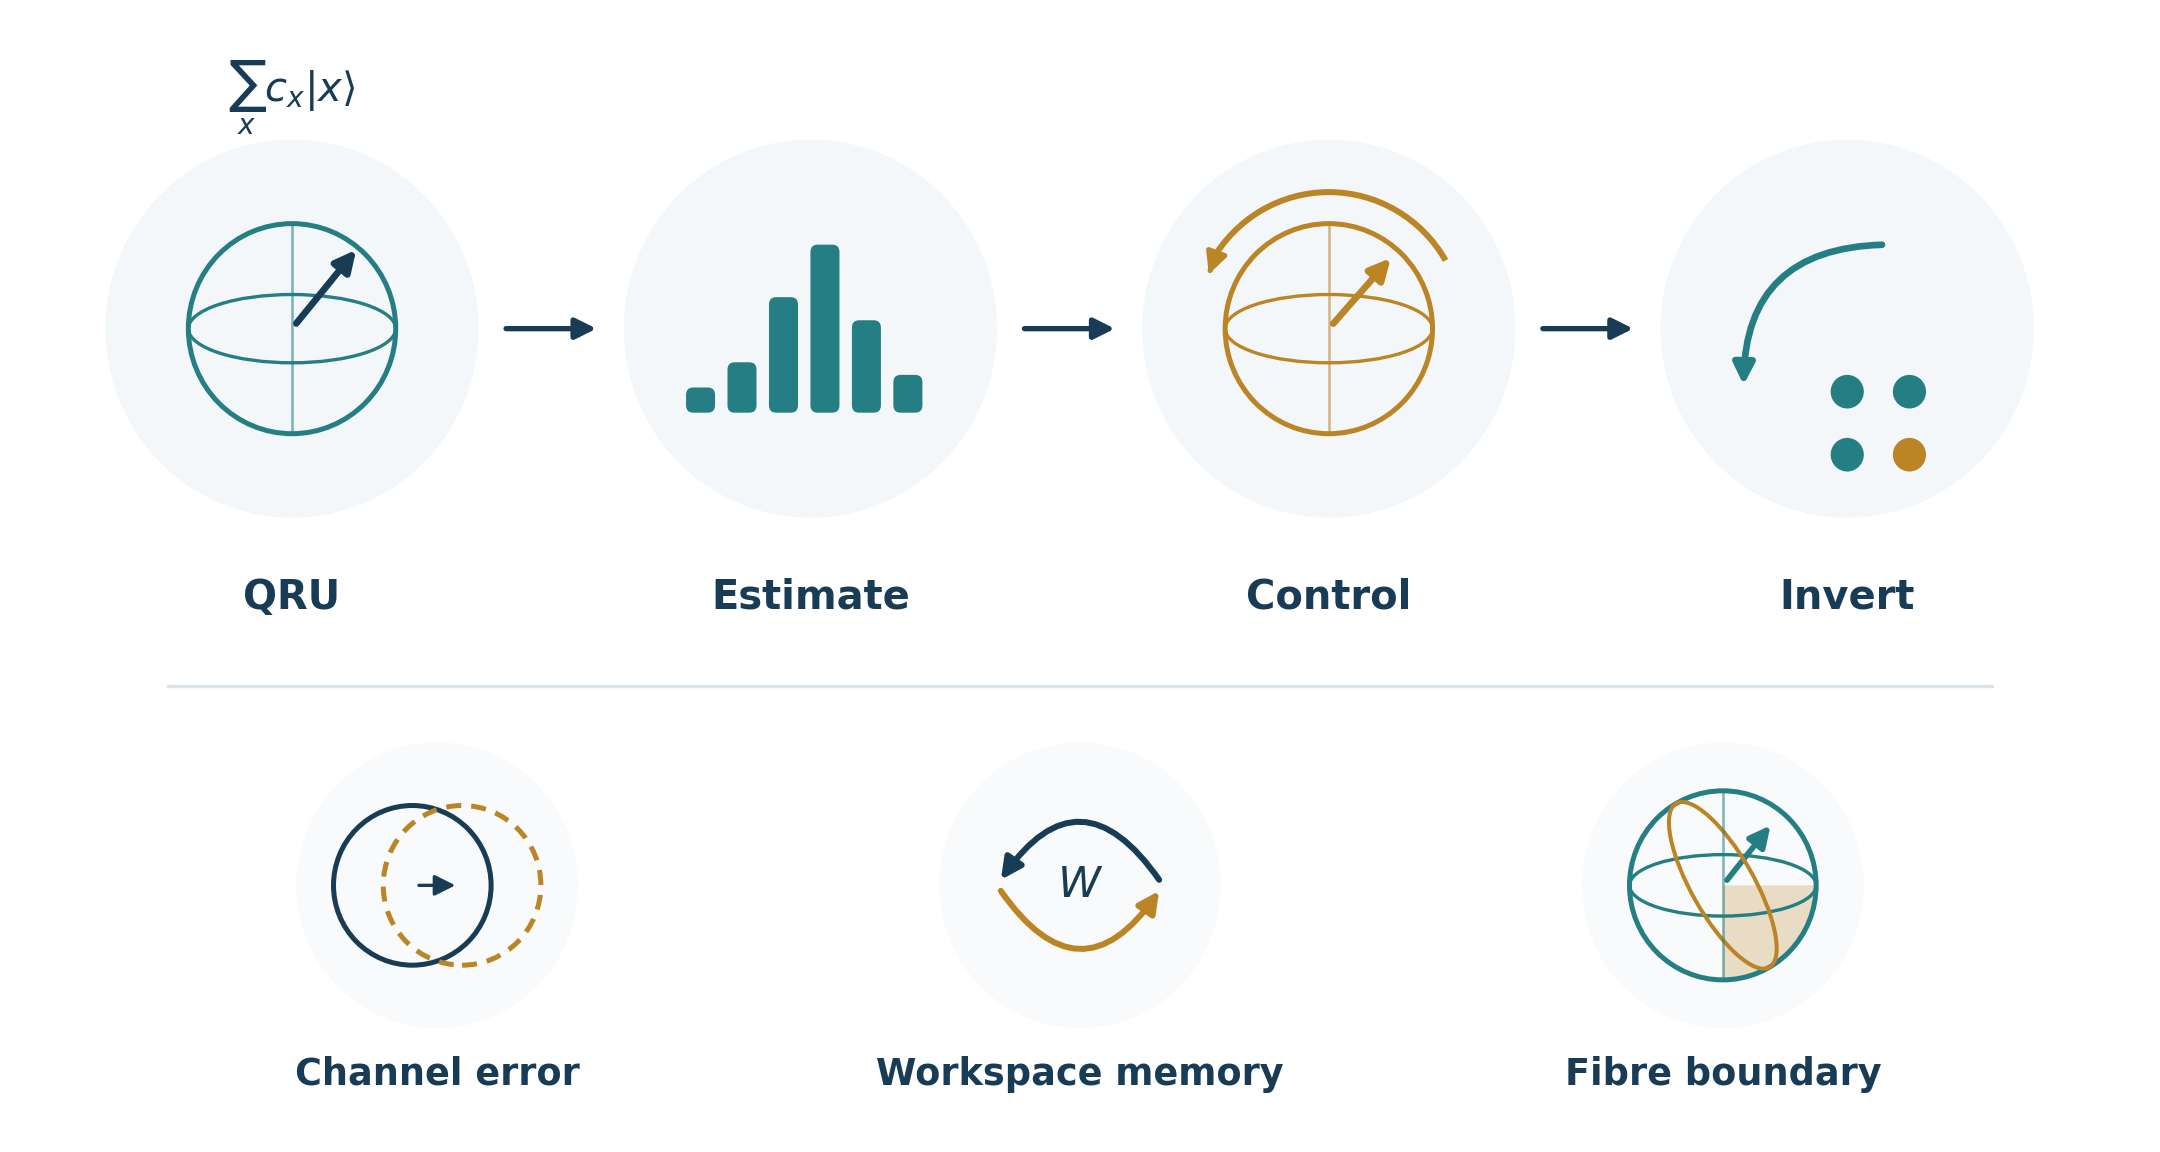

### C01 qru loading

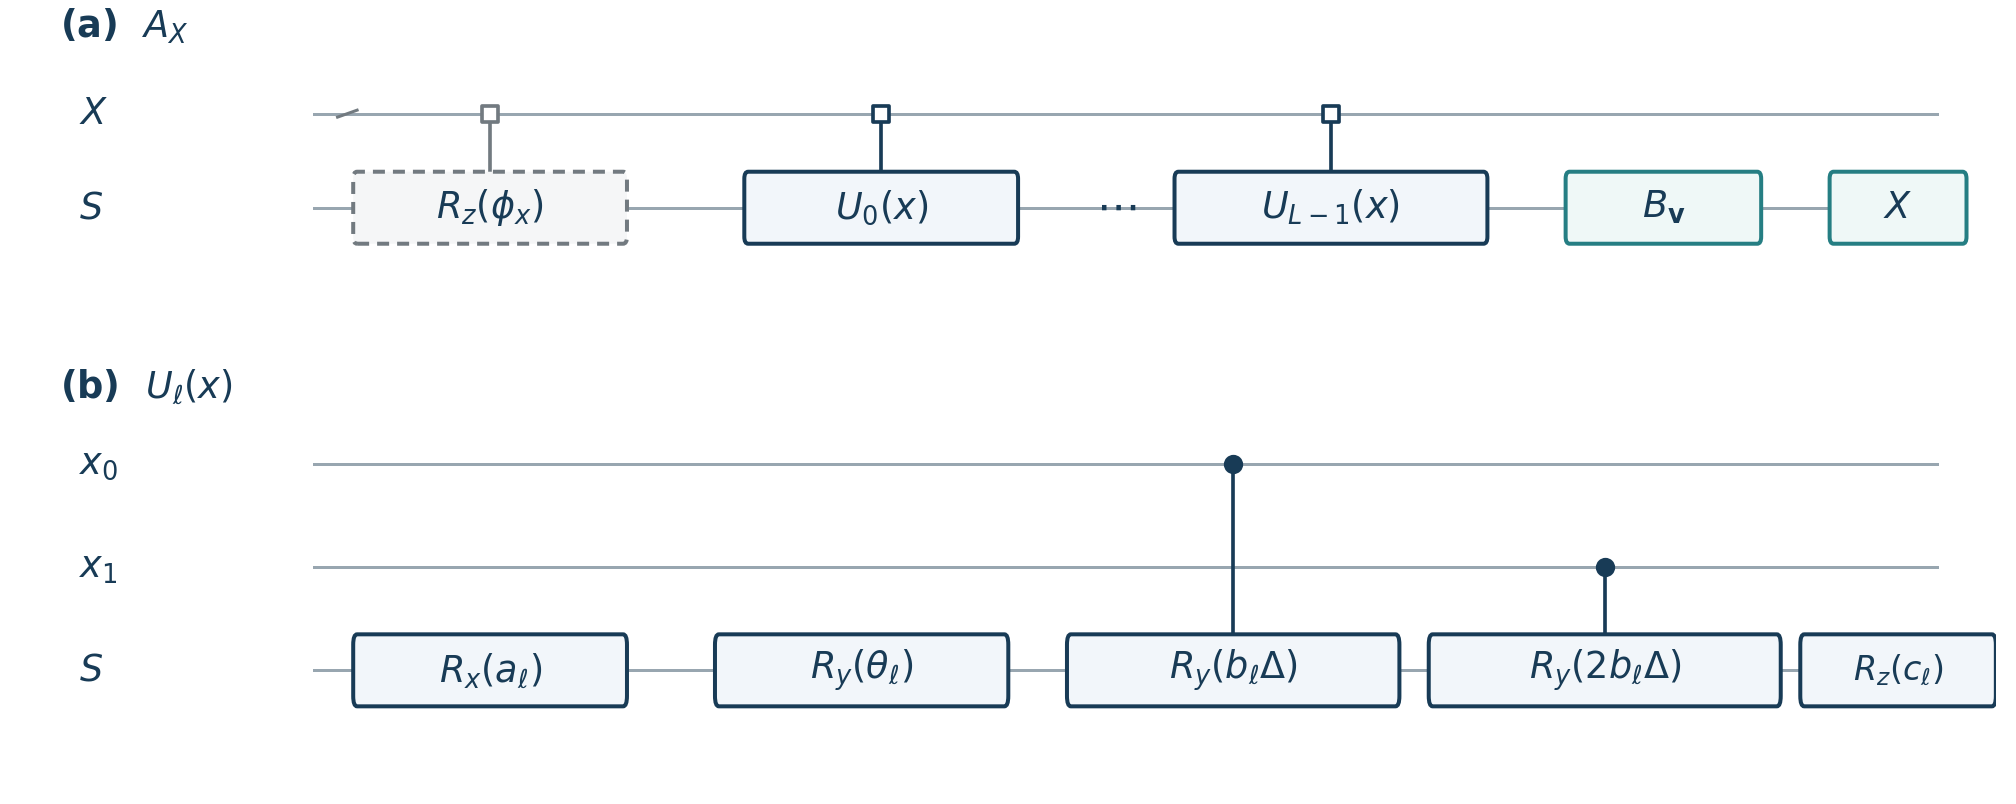

### C02 service estimator

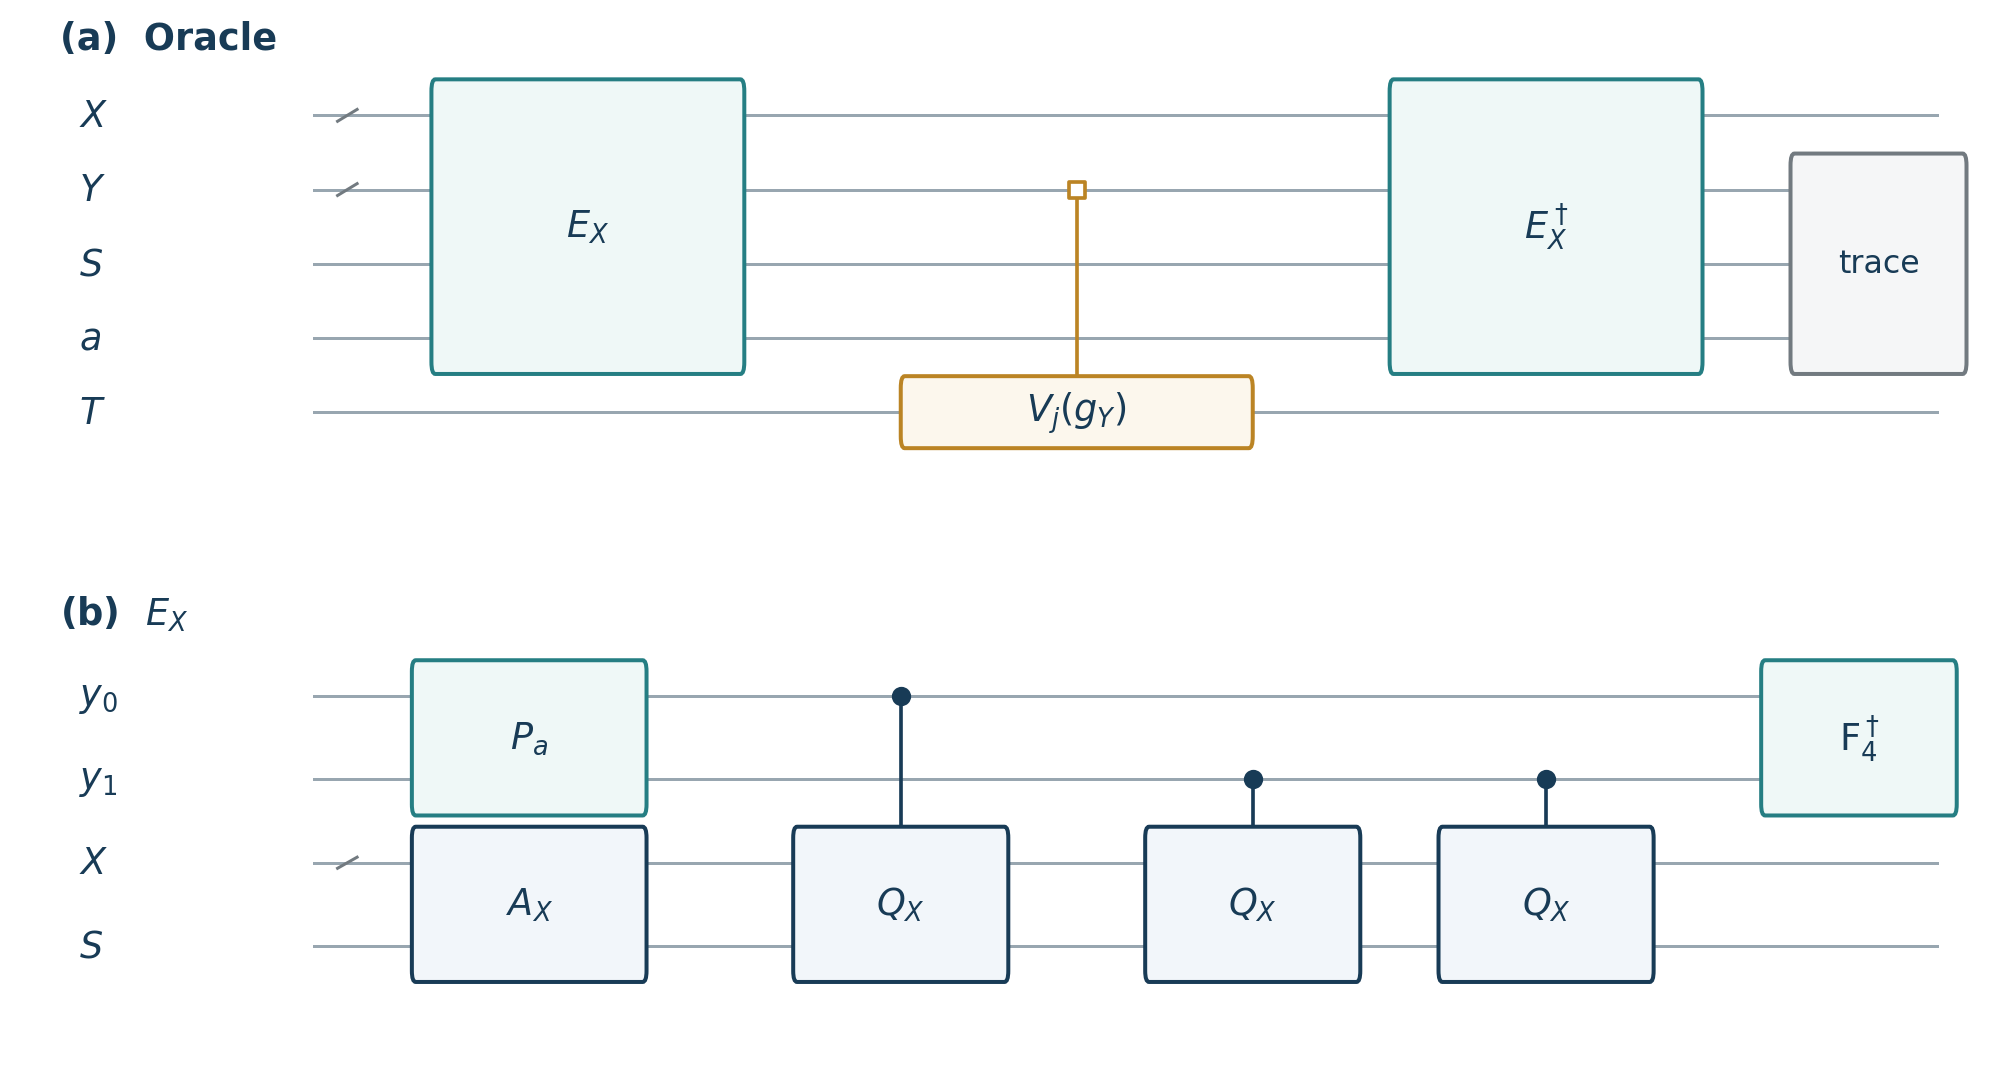

### 01 contract

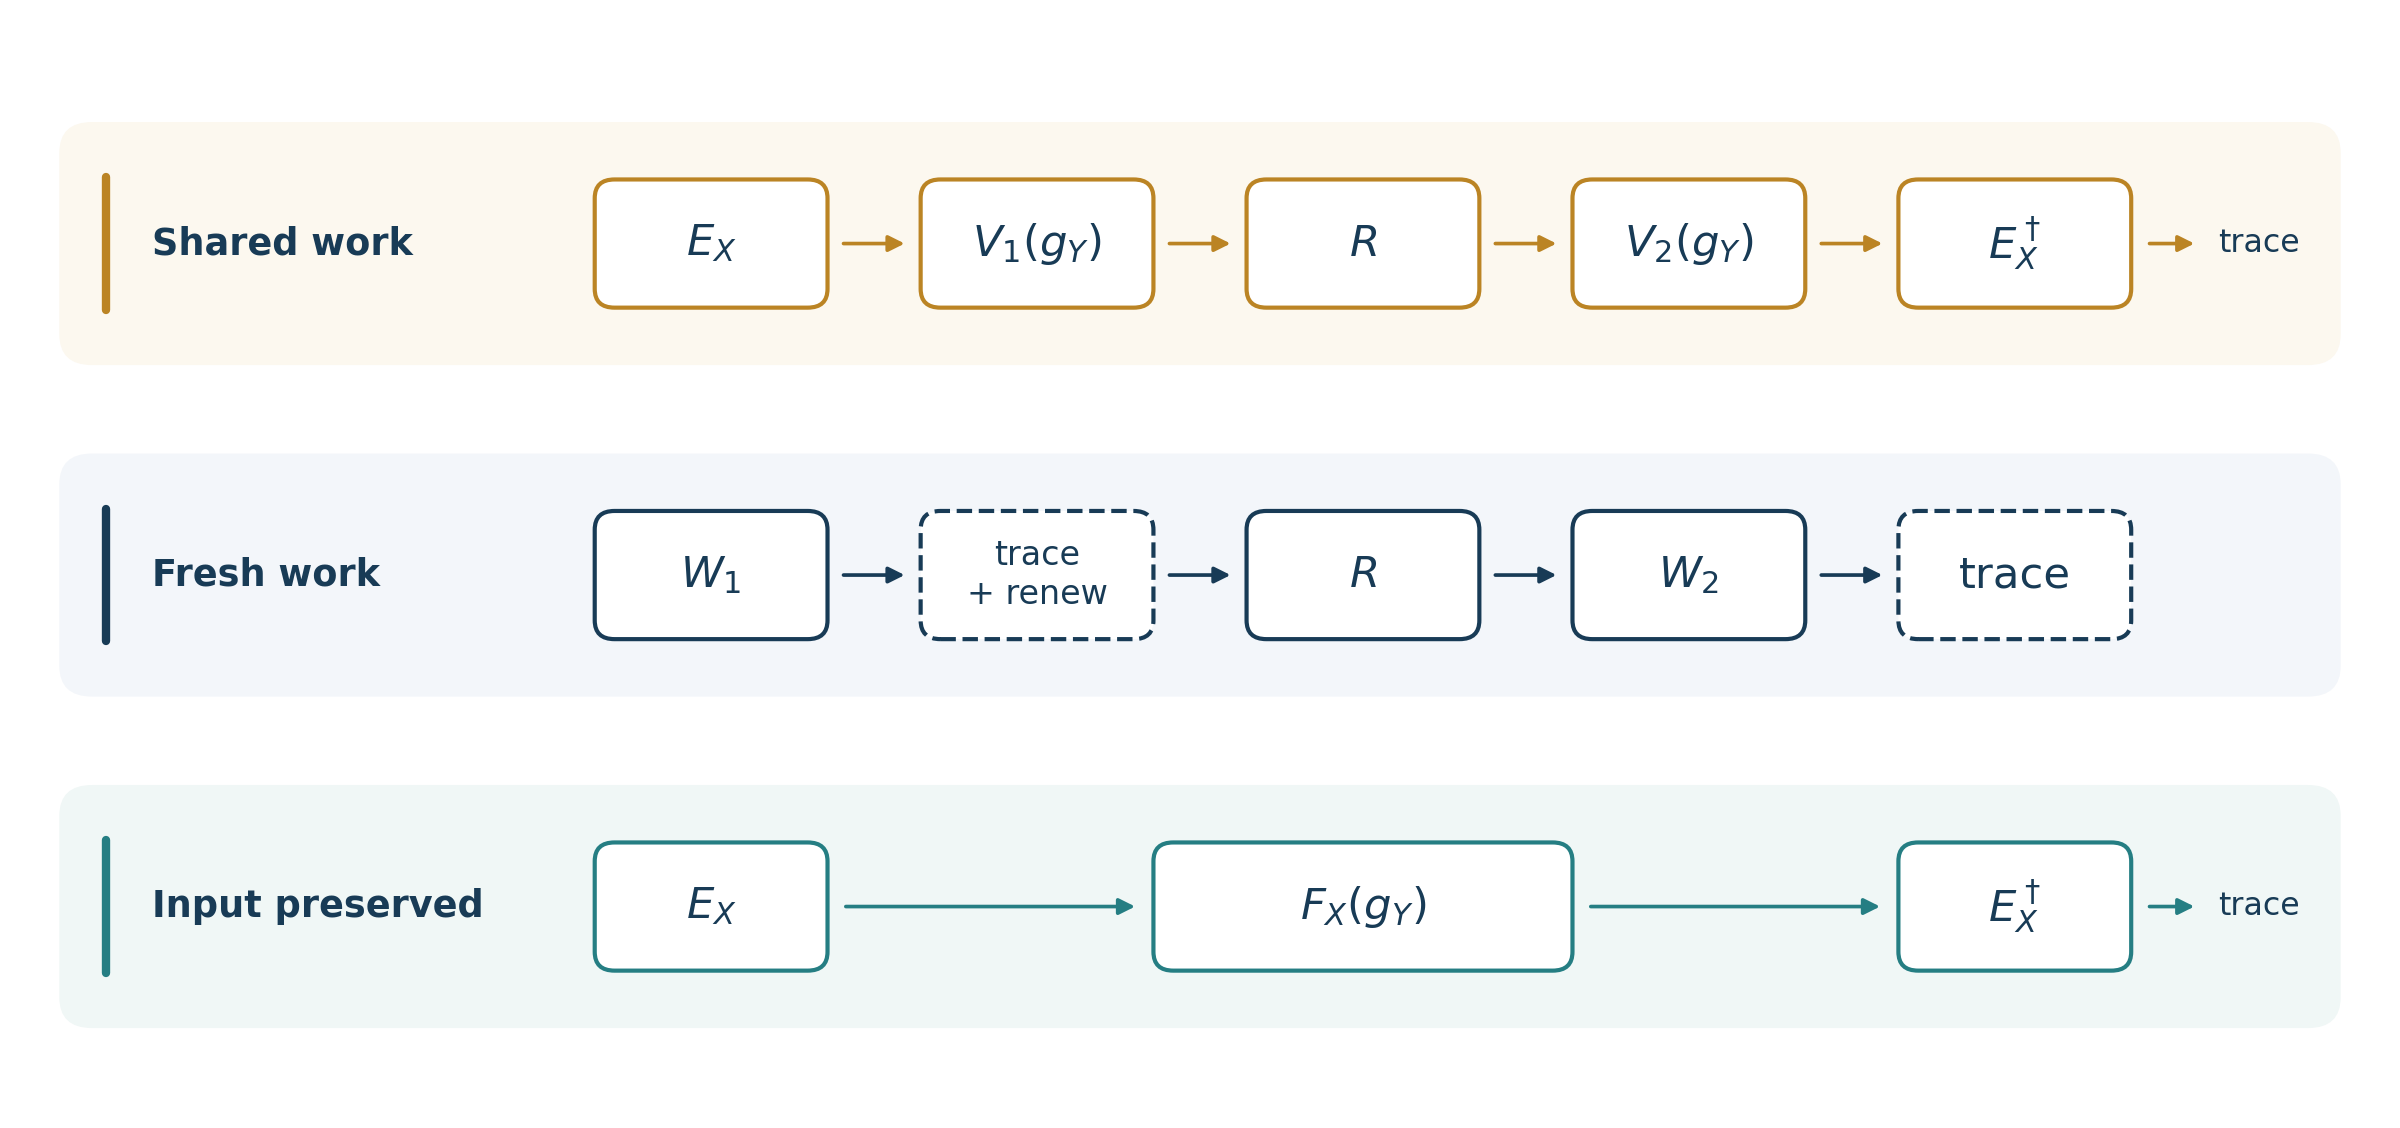

### 02 precision

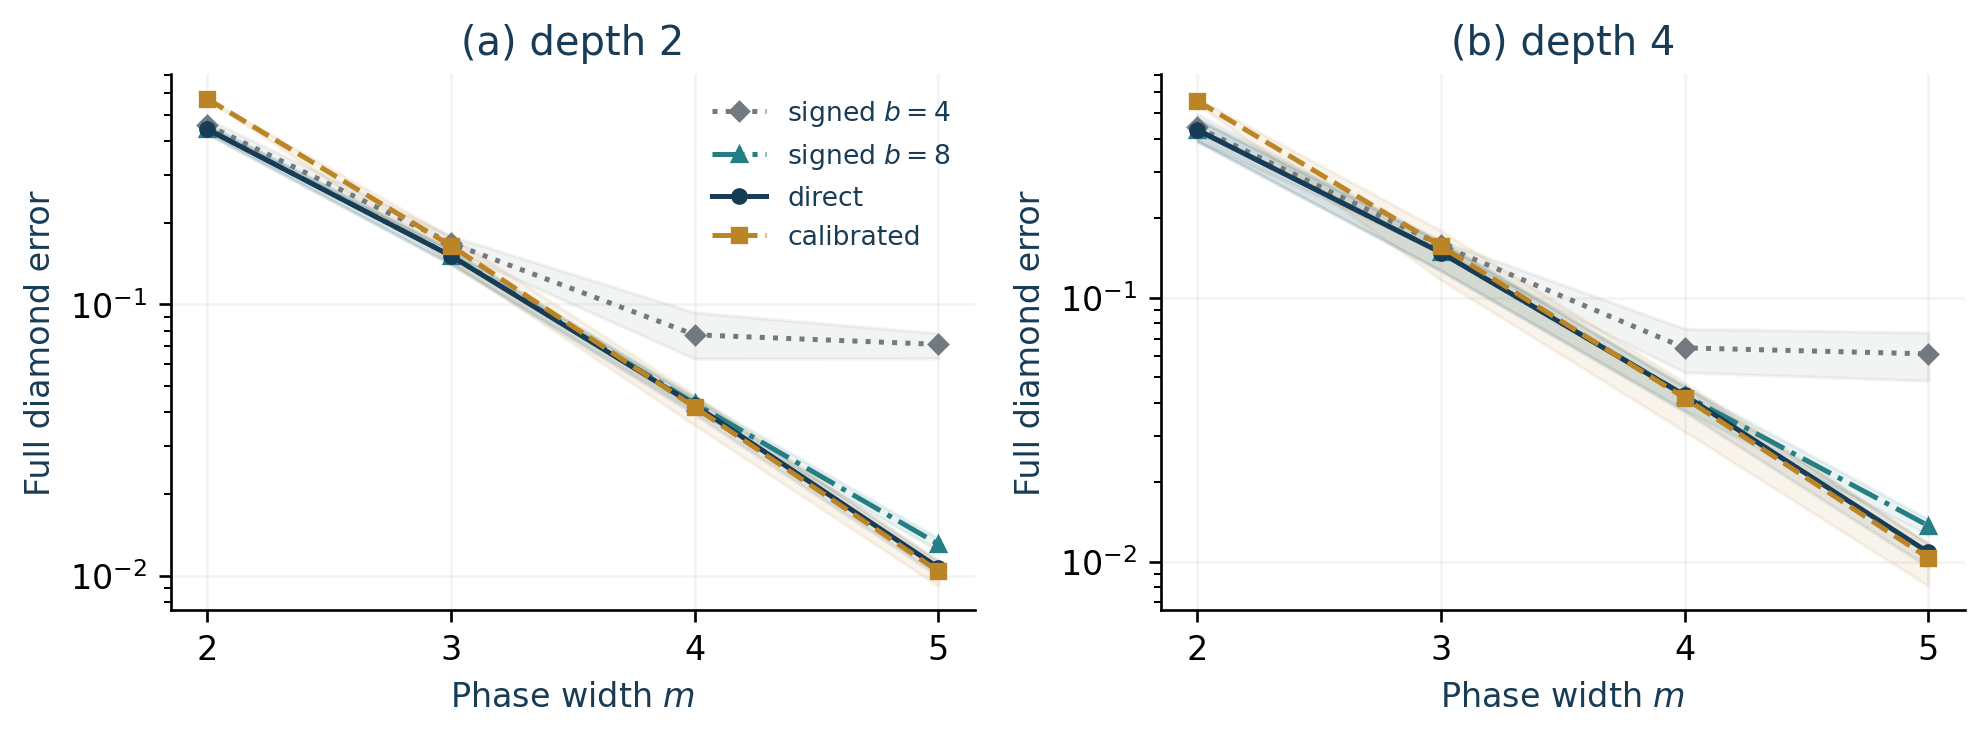

### 03 memory

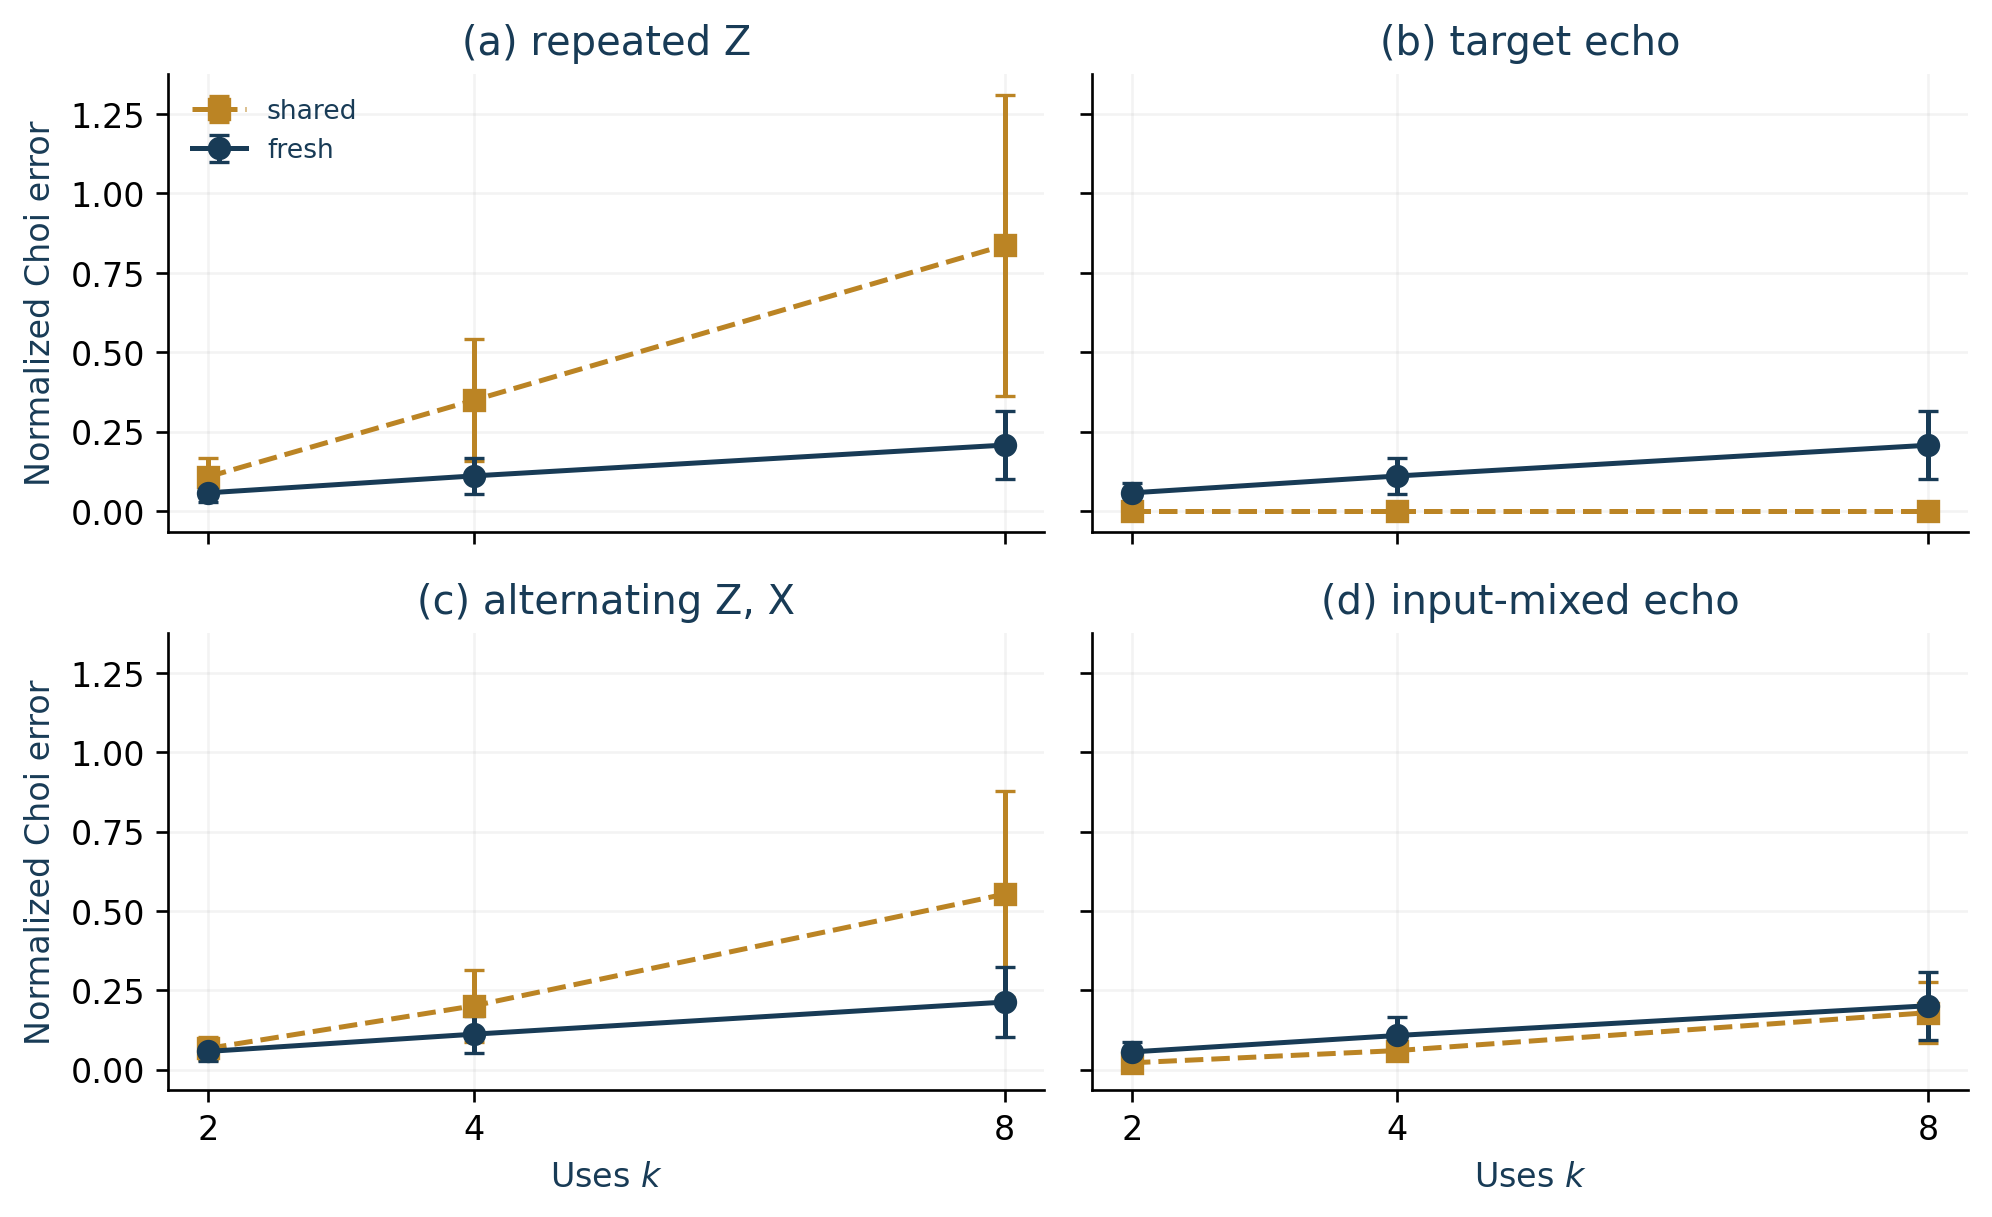

### 04 fibre

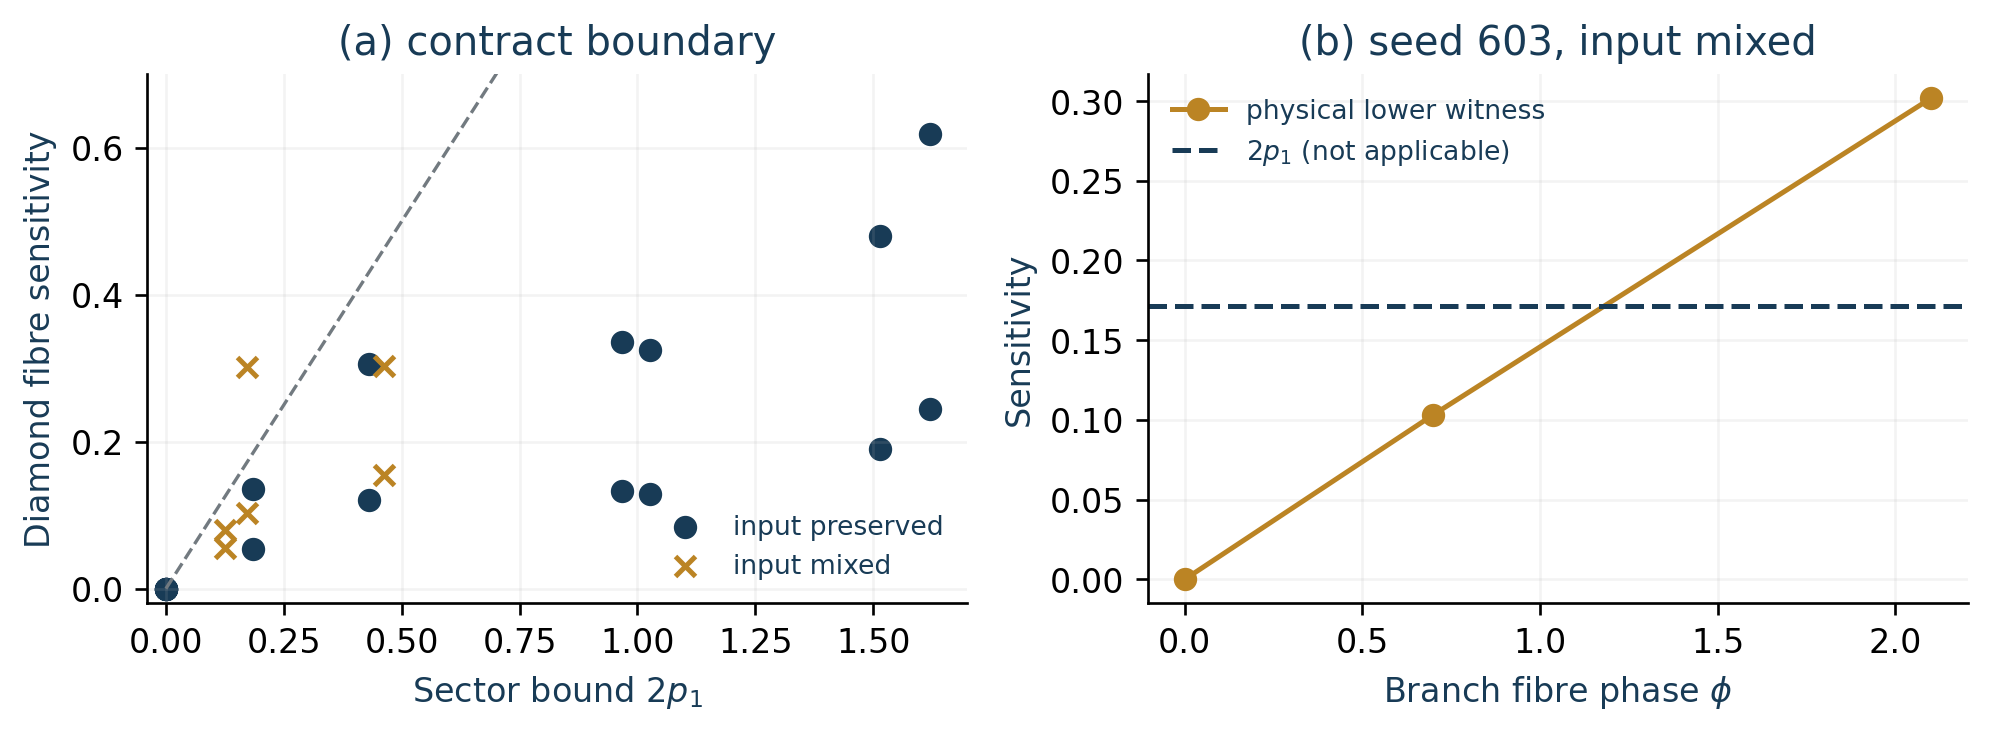

### 05 noise

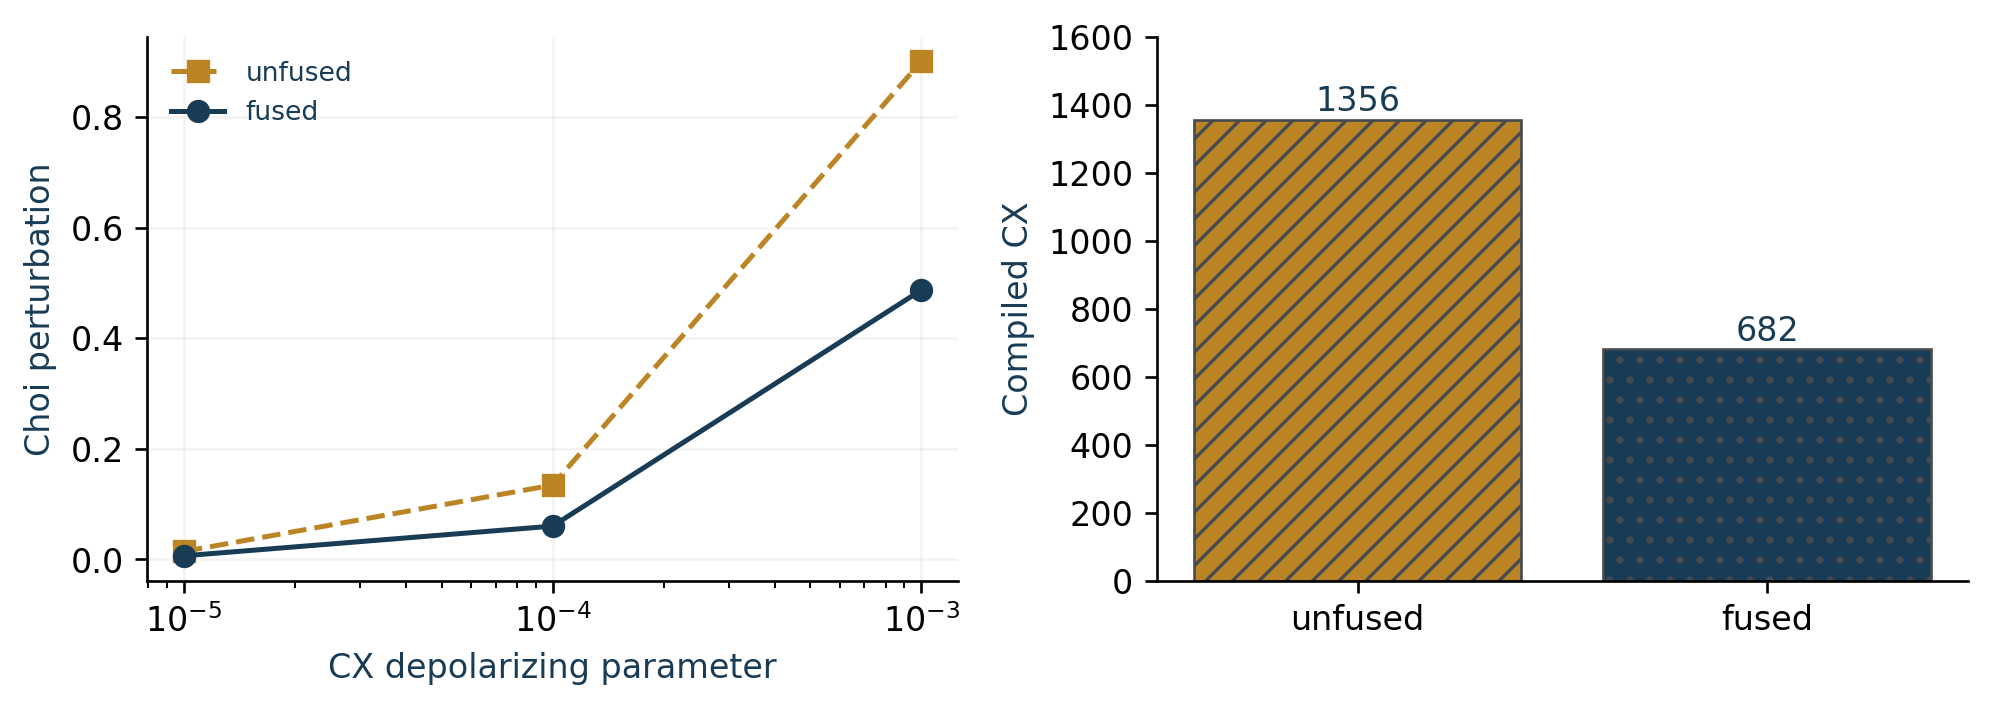

### C03 grover window

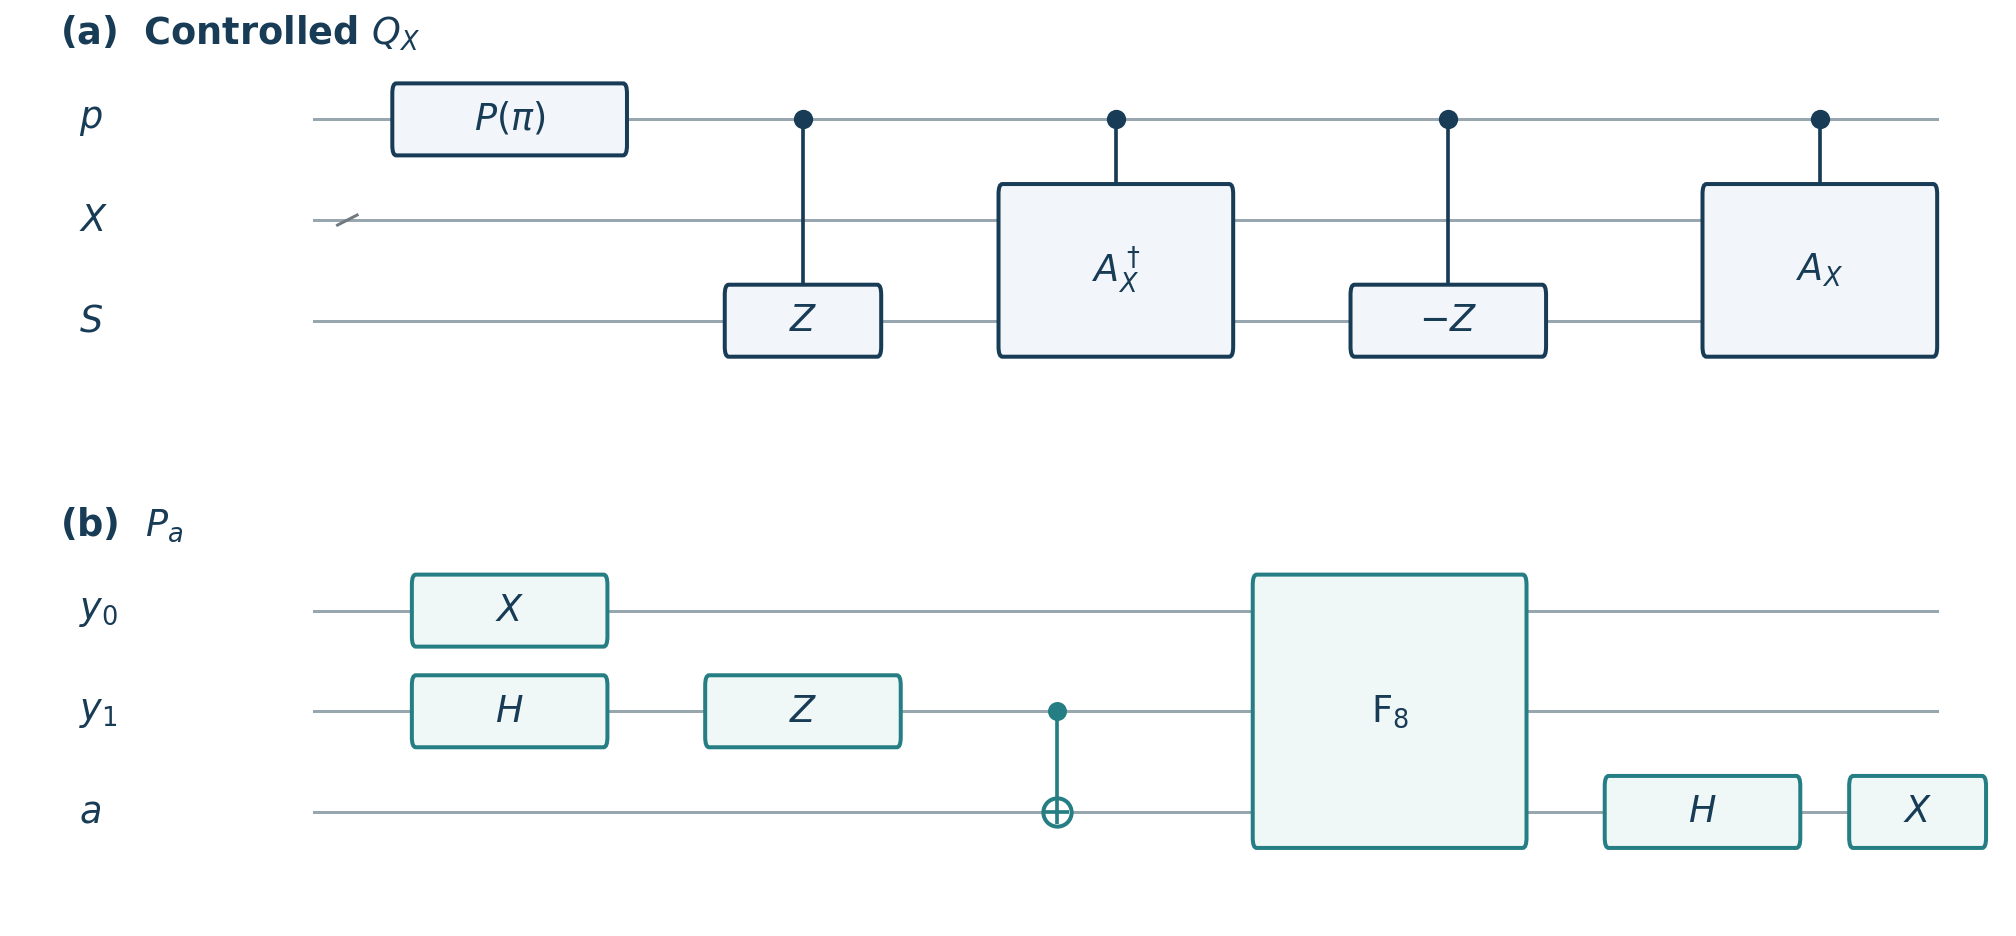

### C04 target control

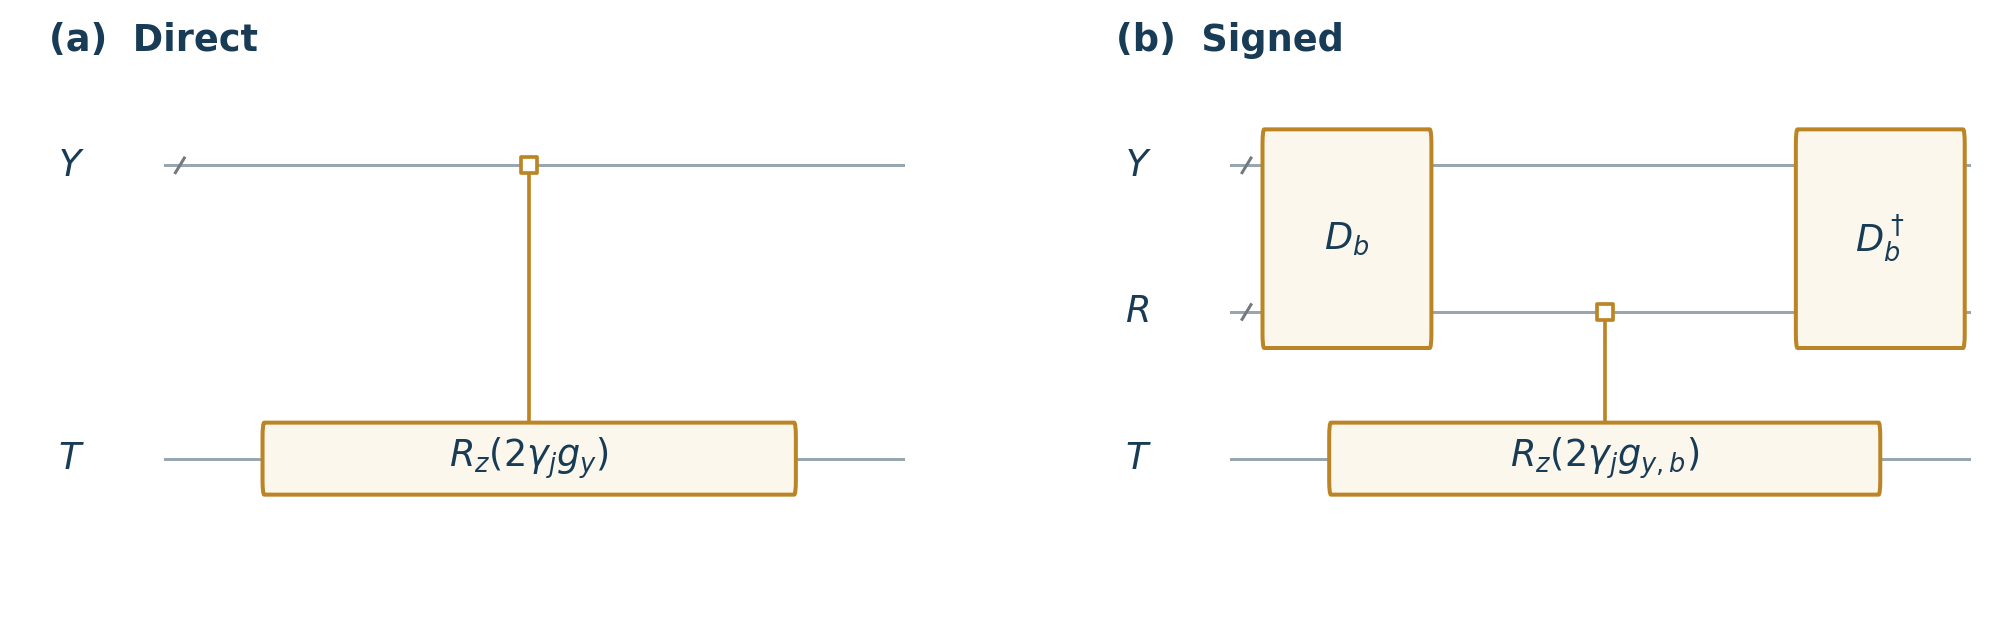

### A resources

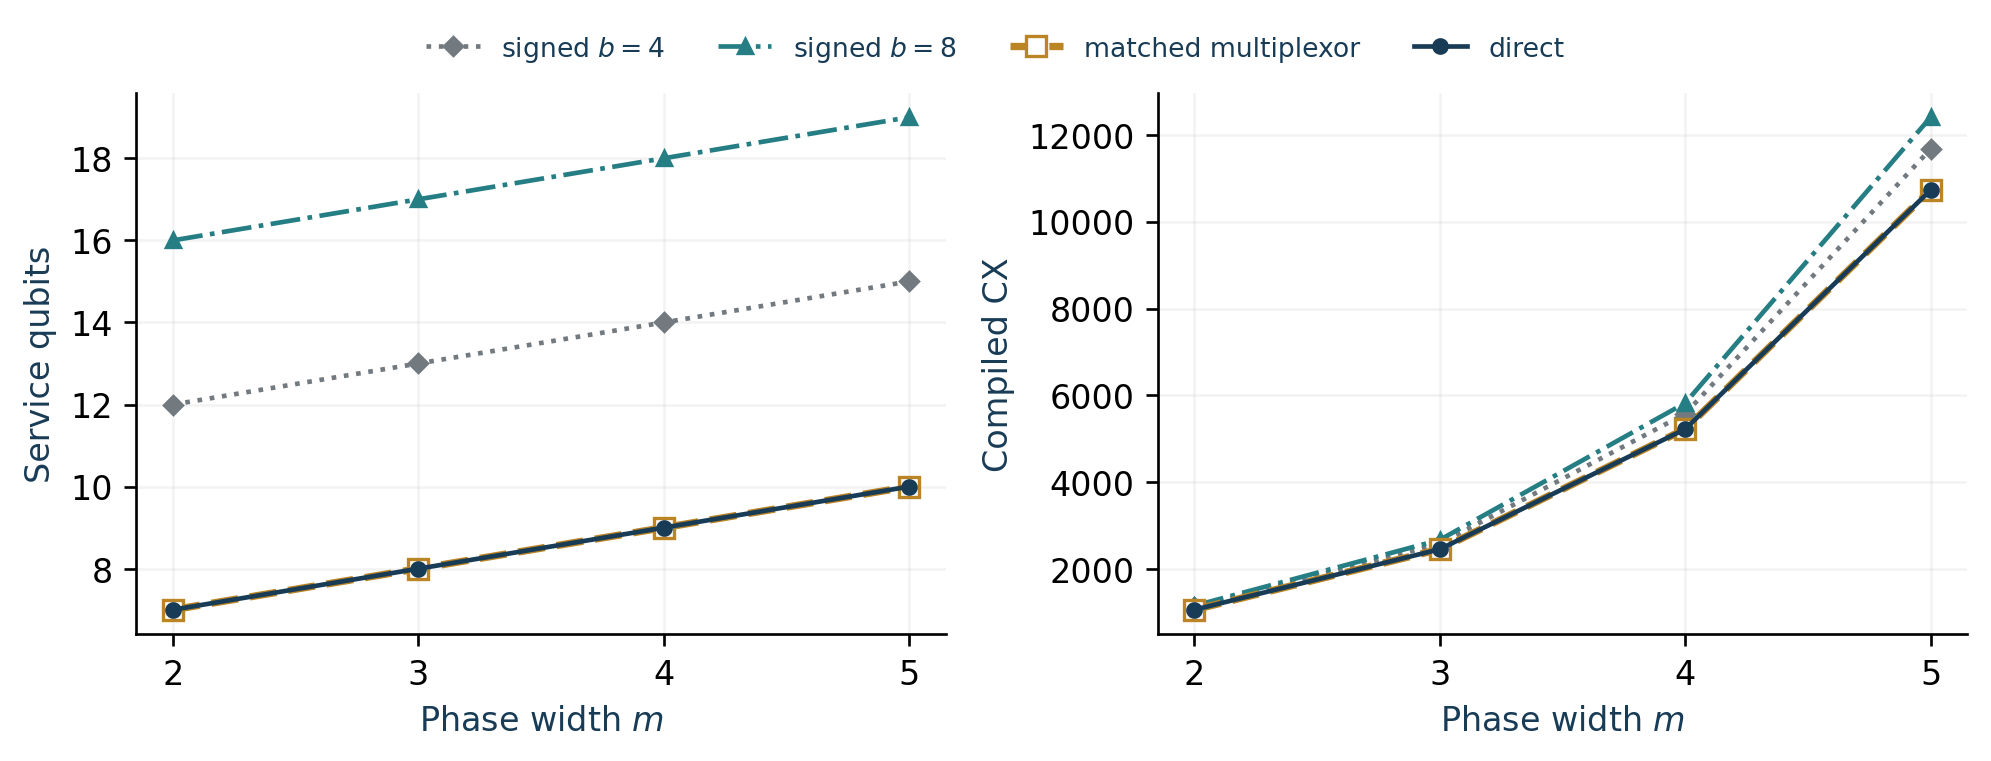

### A calibration

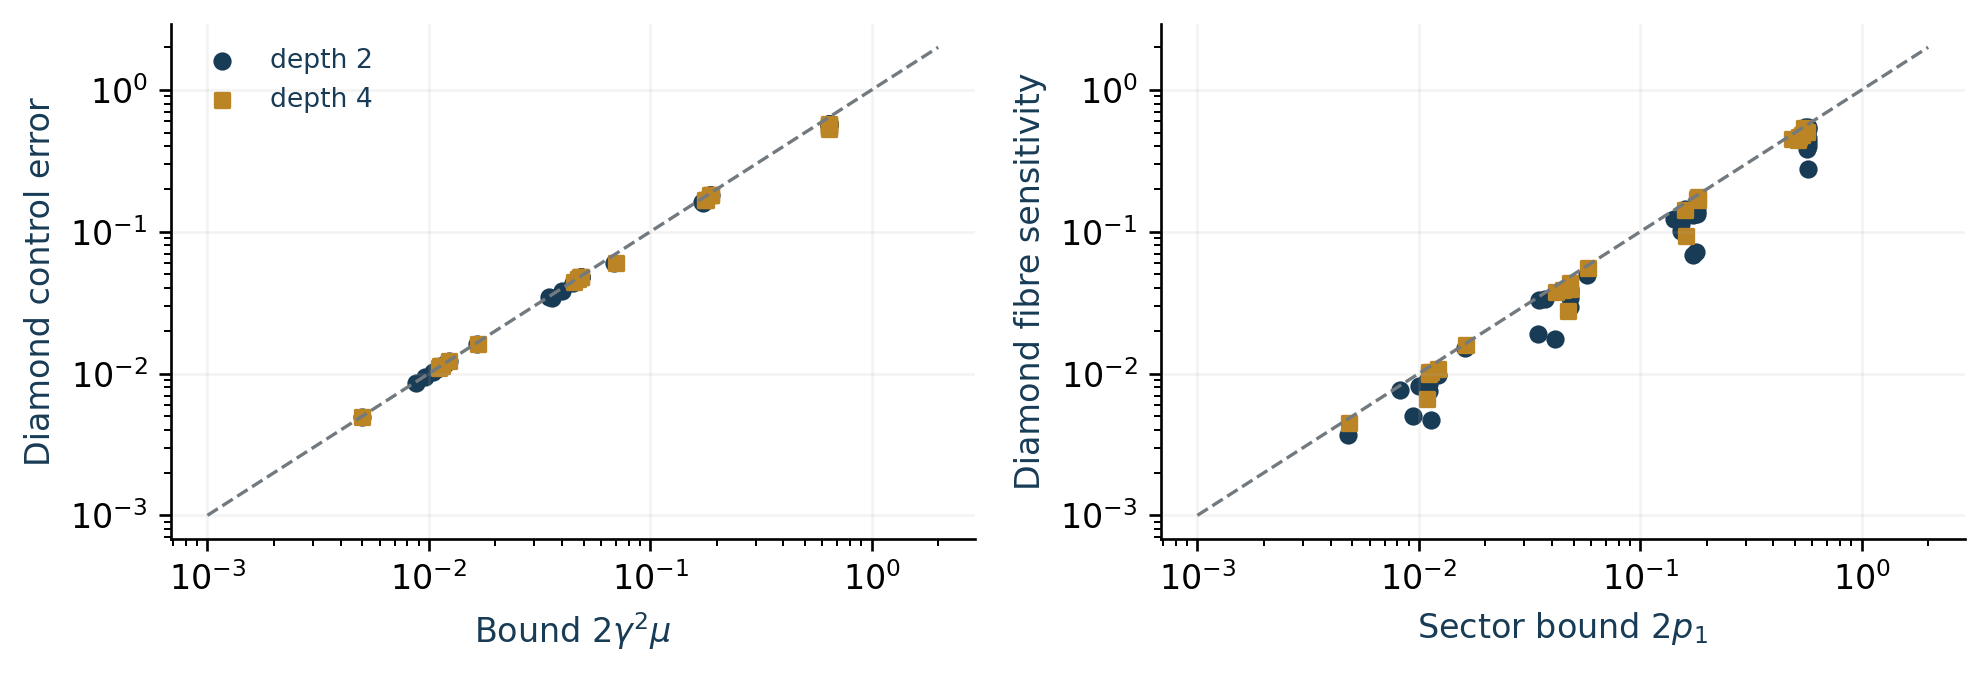

### A 06 bit allocation

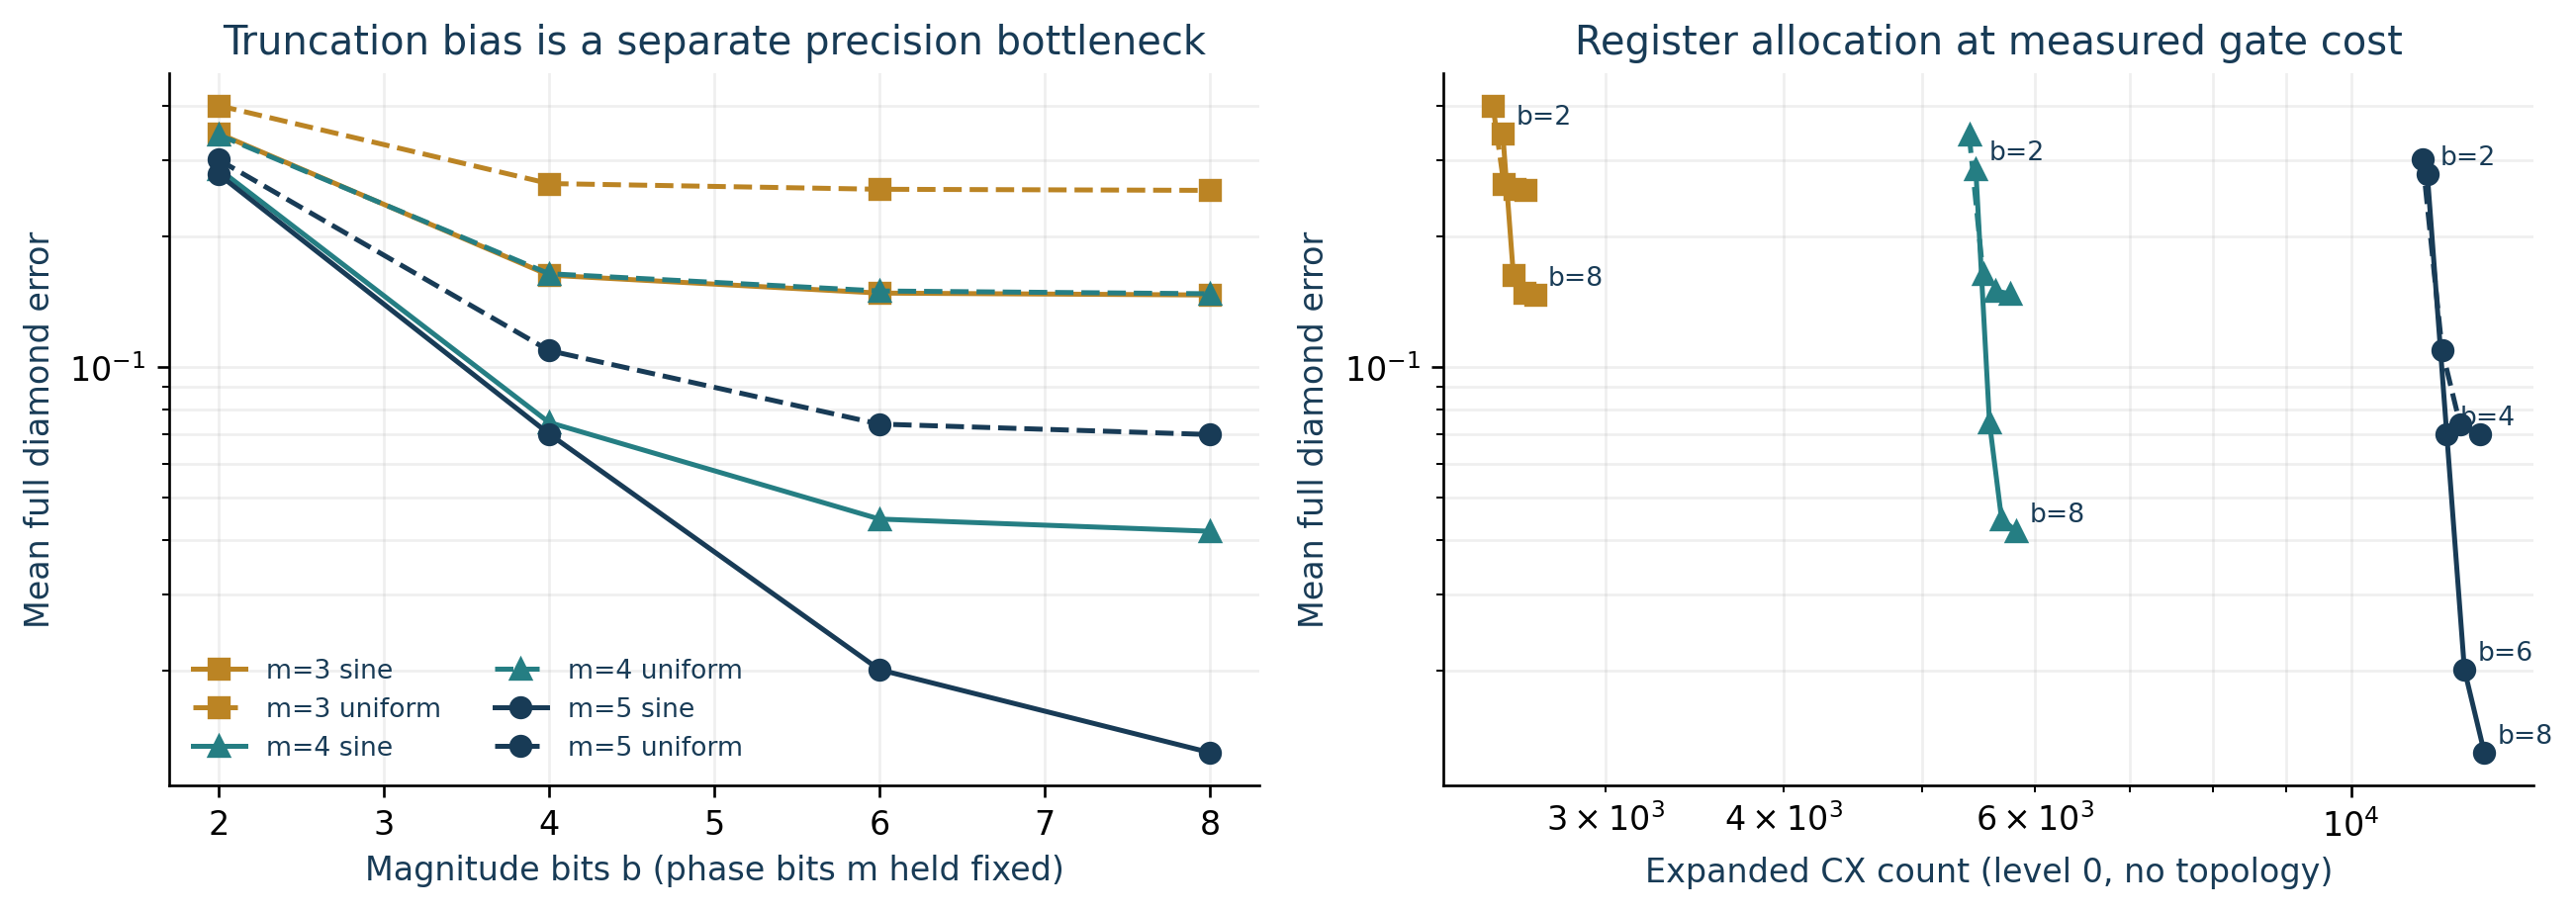

### A 03 scalar vs channel

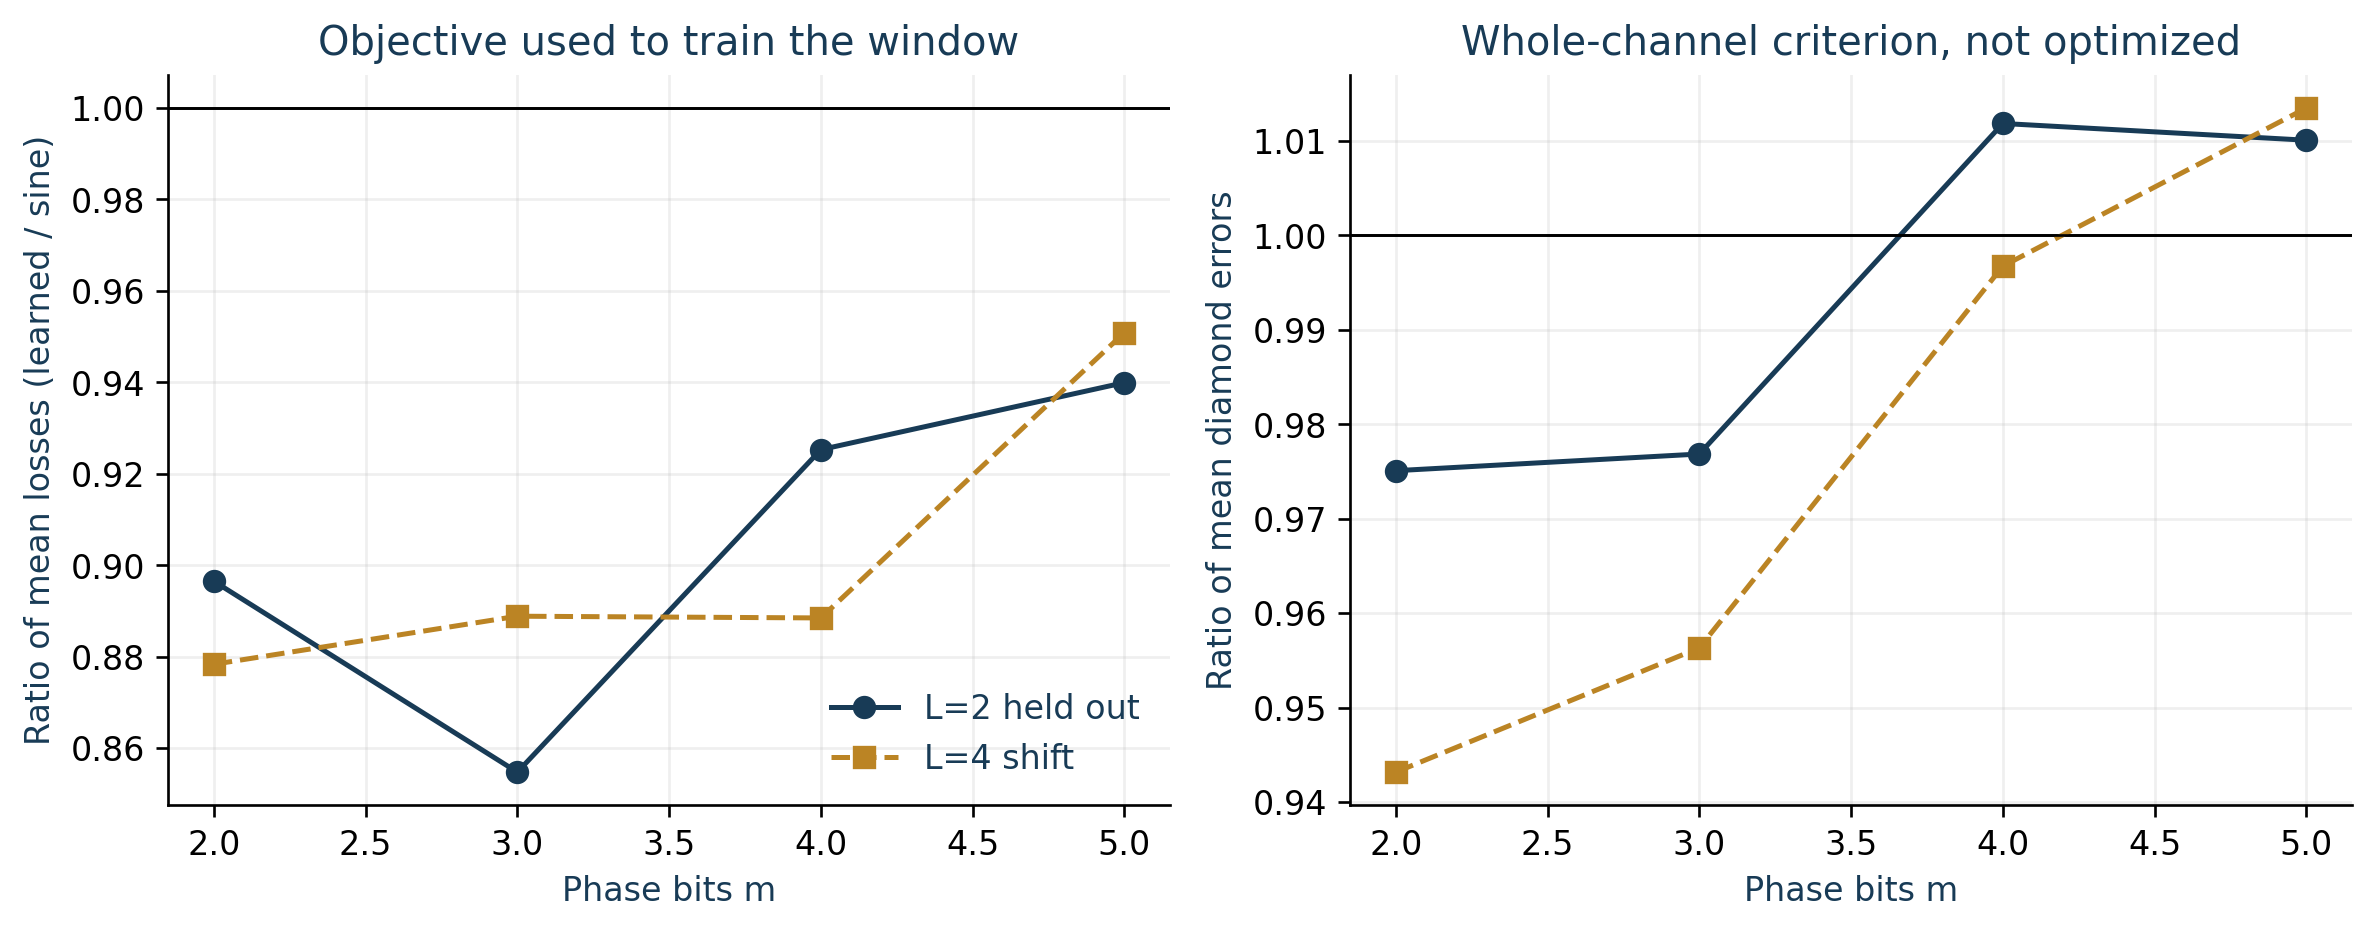

### A 07 quaternion fibre

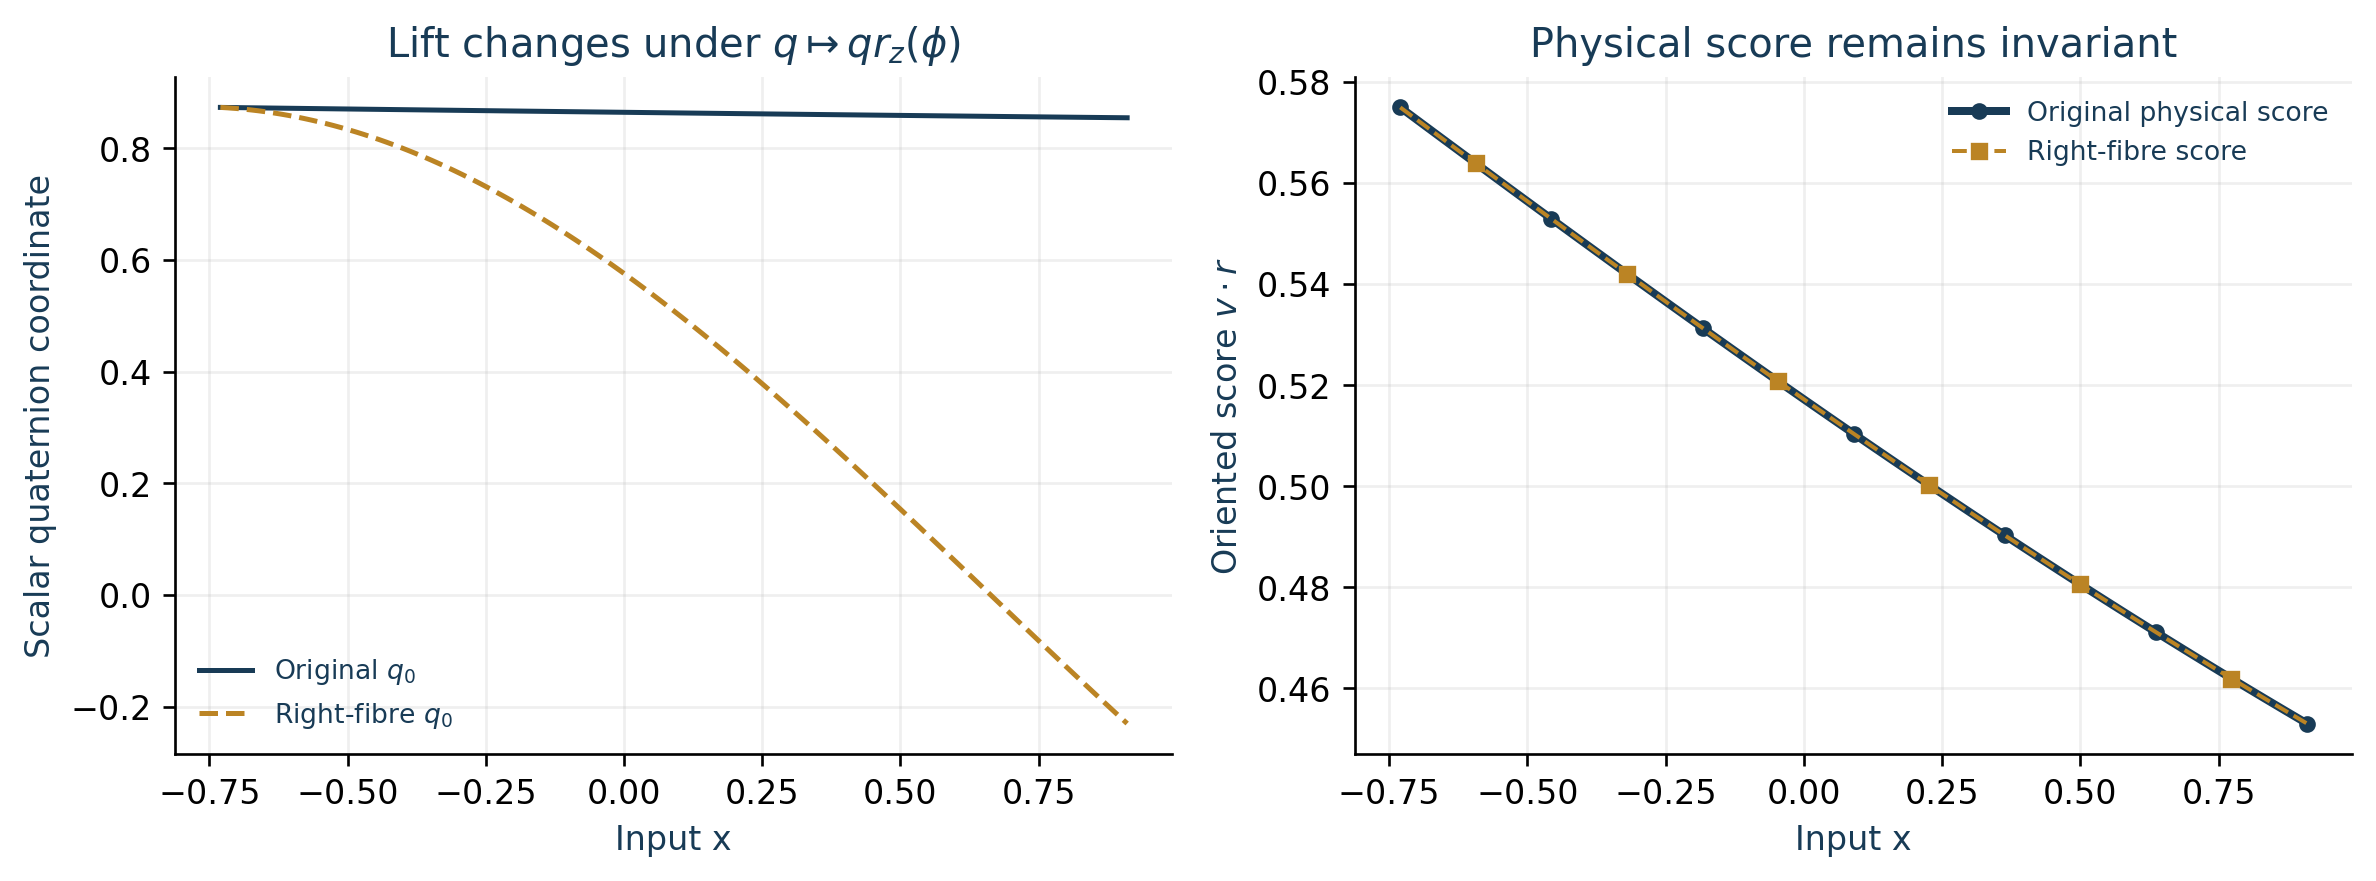

### A 02 fibre cancellation

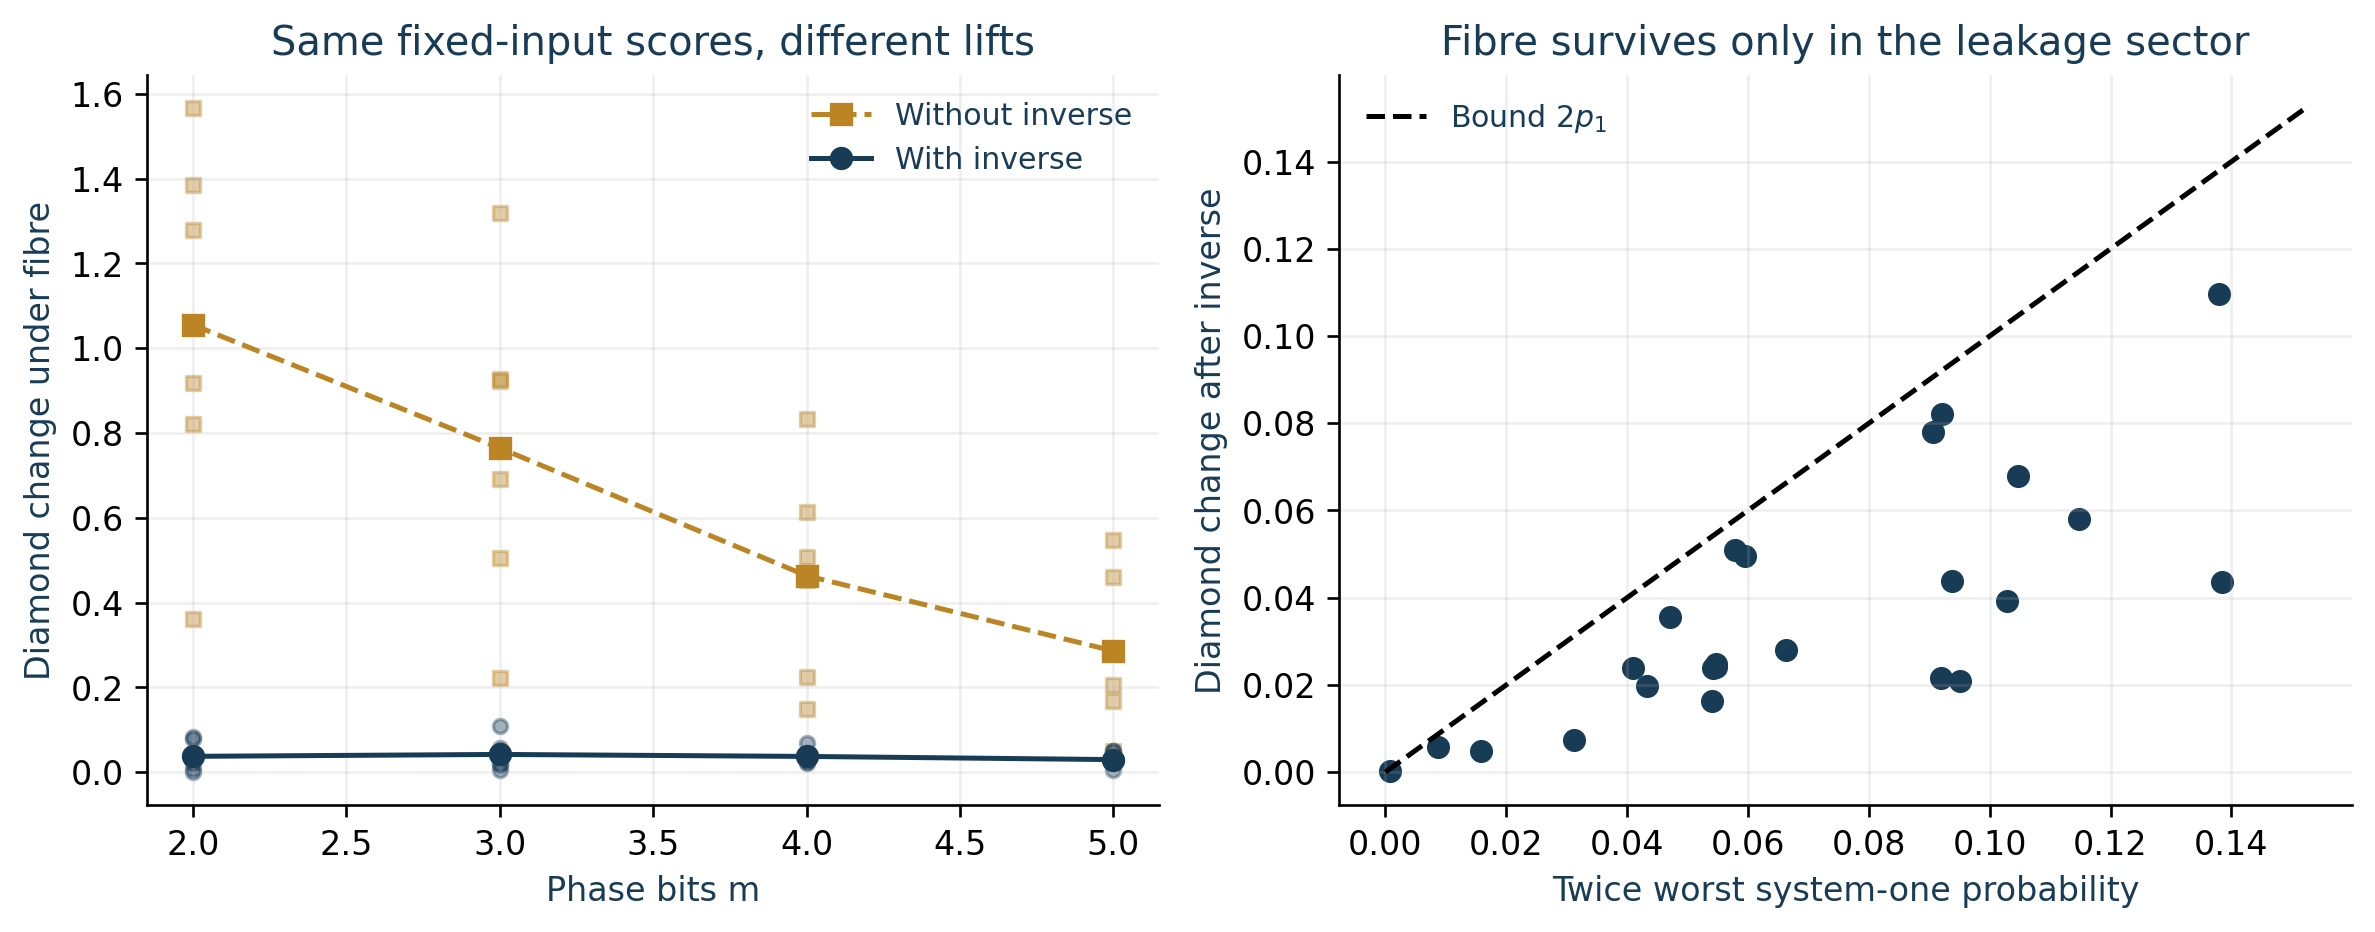

### A 04 dephasing intervention

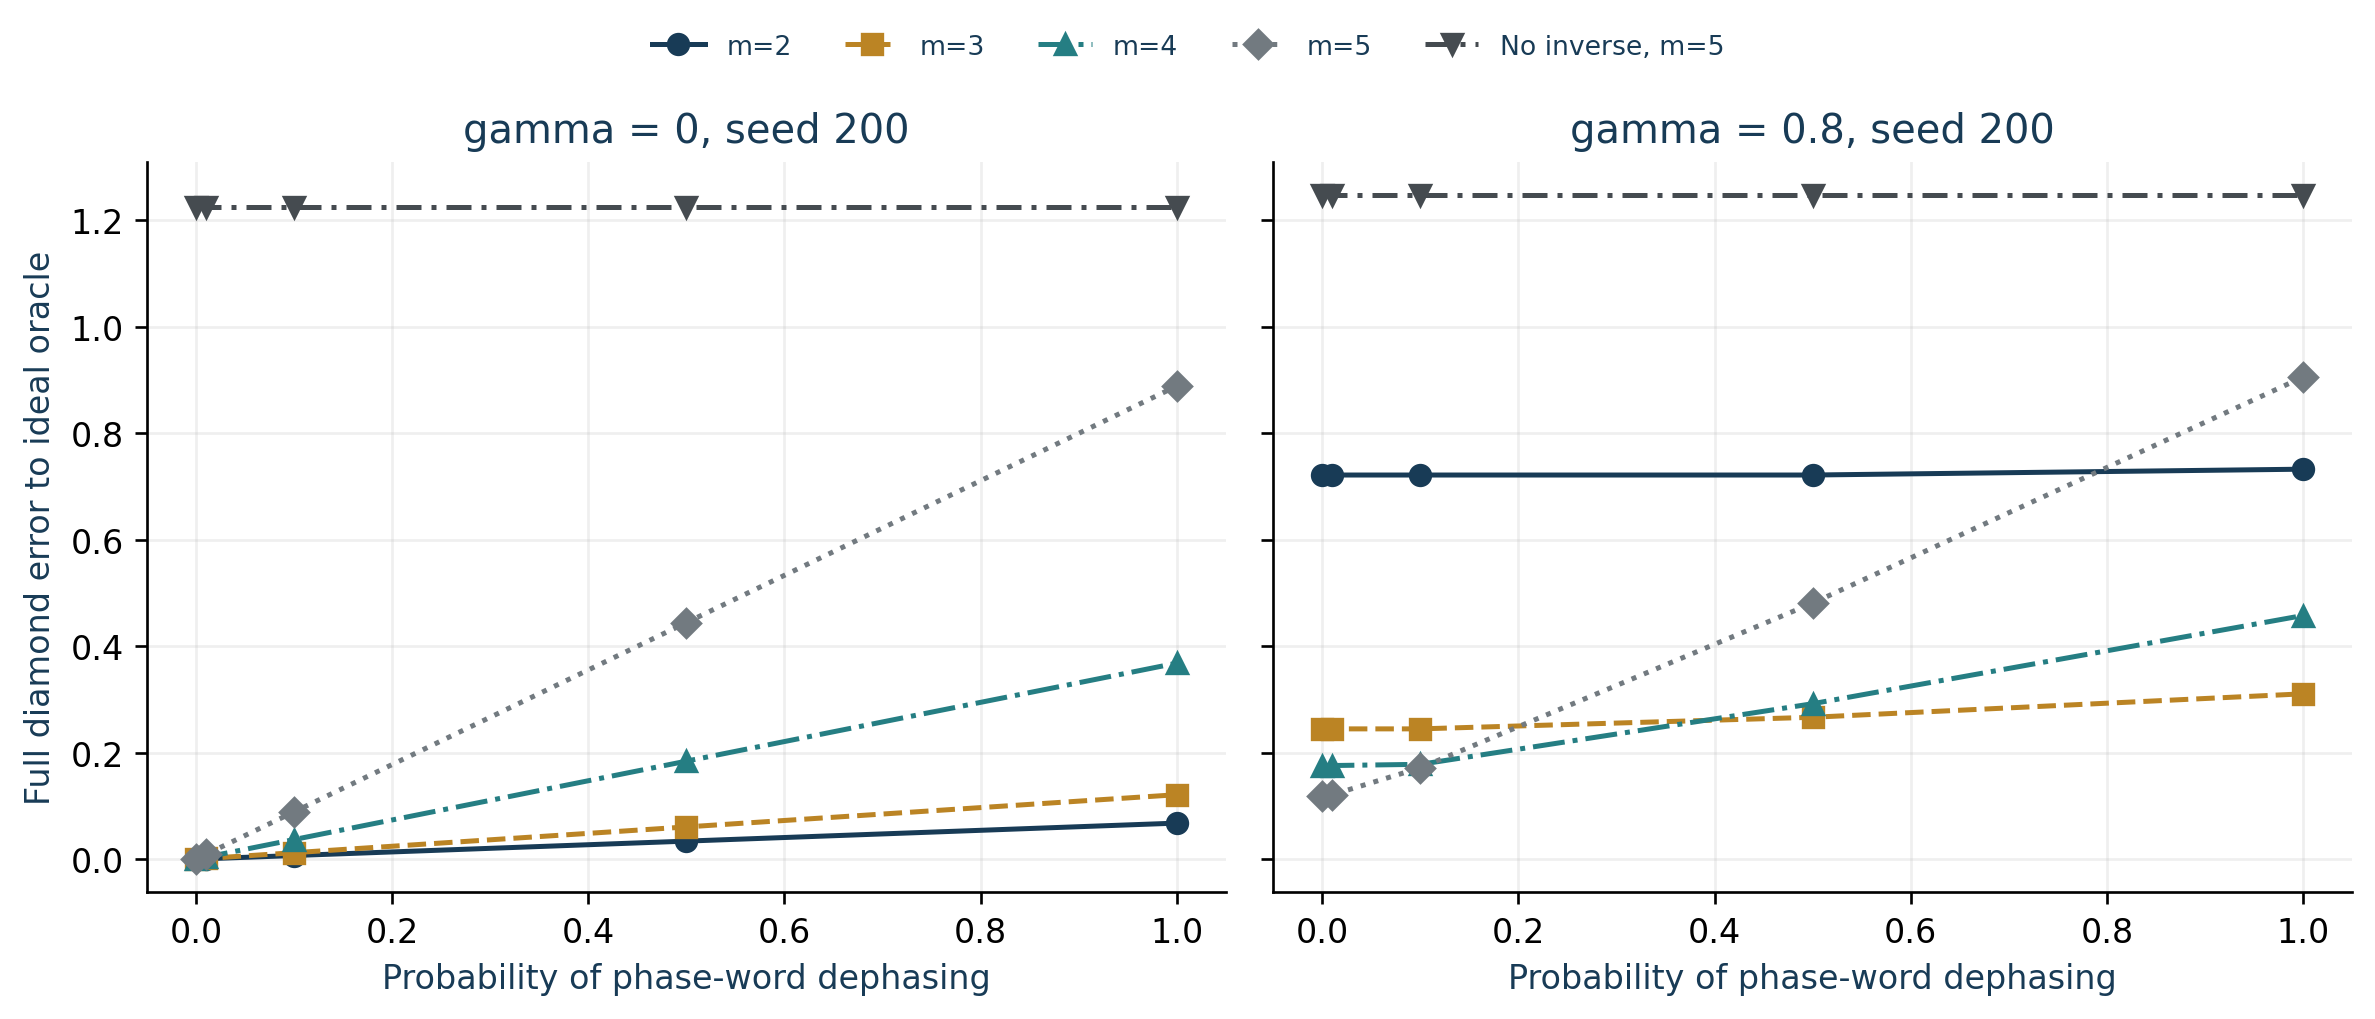

### A reuse

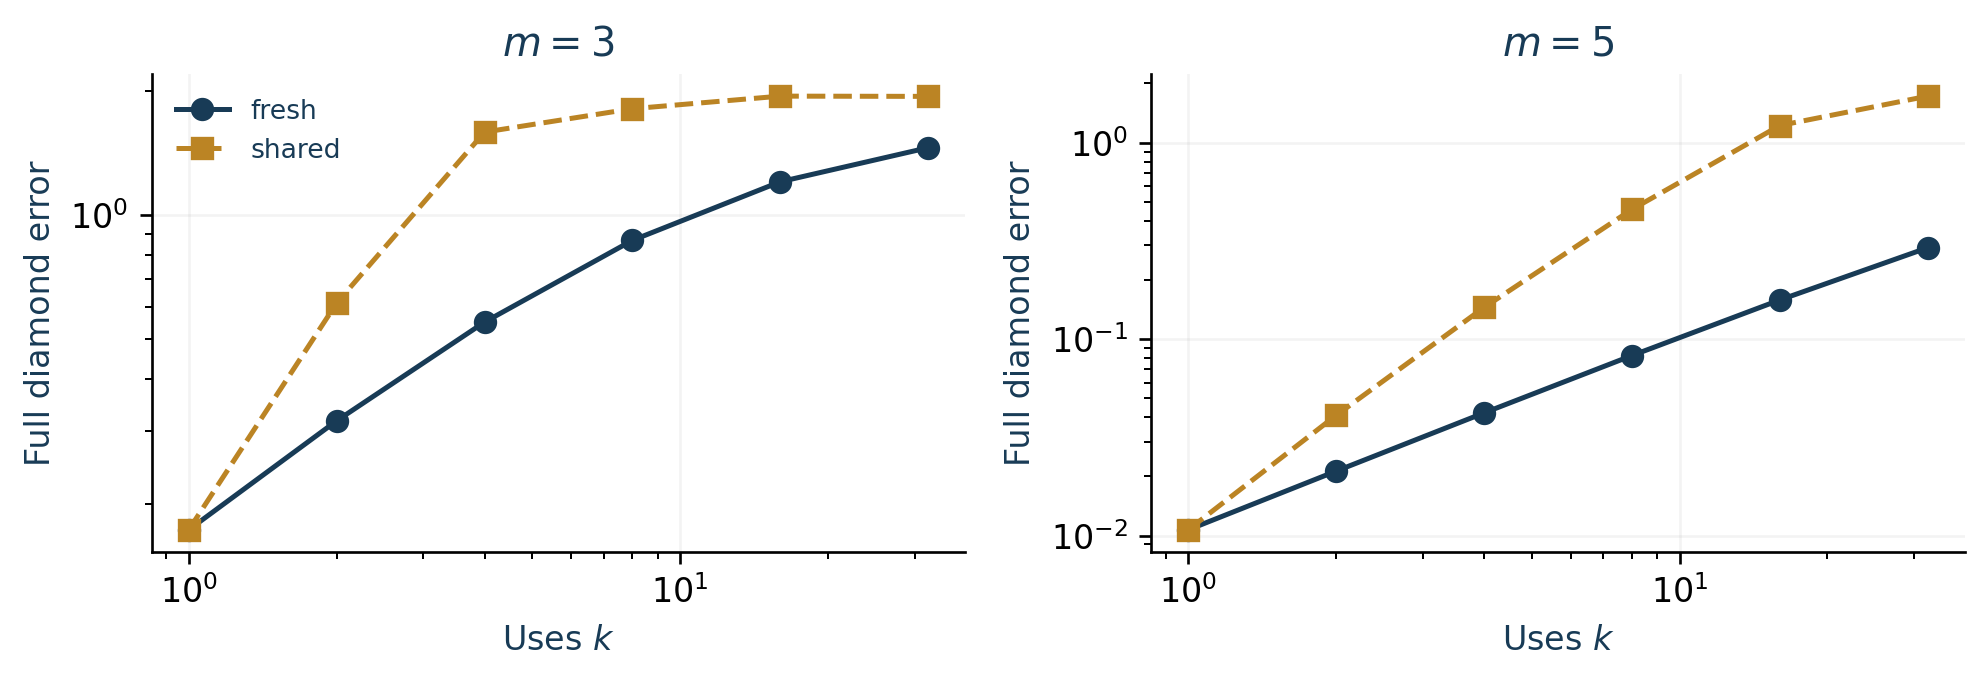

### A01 depth

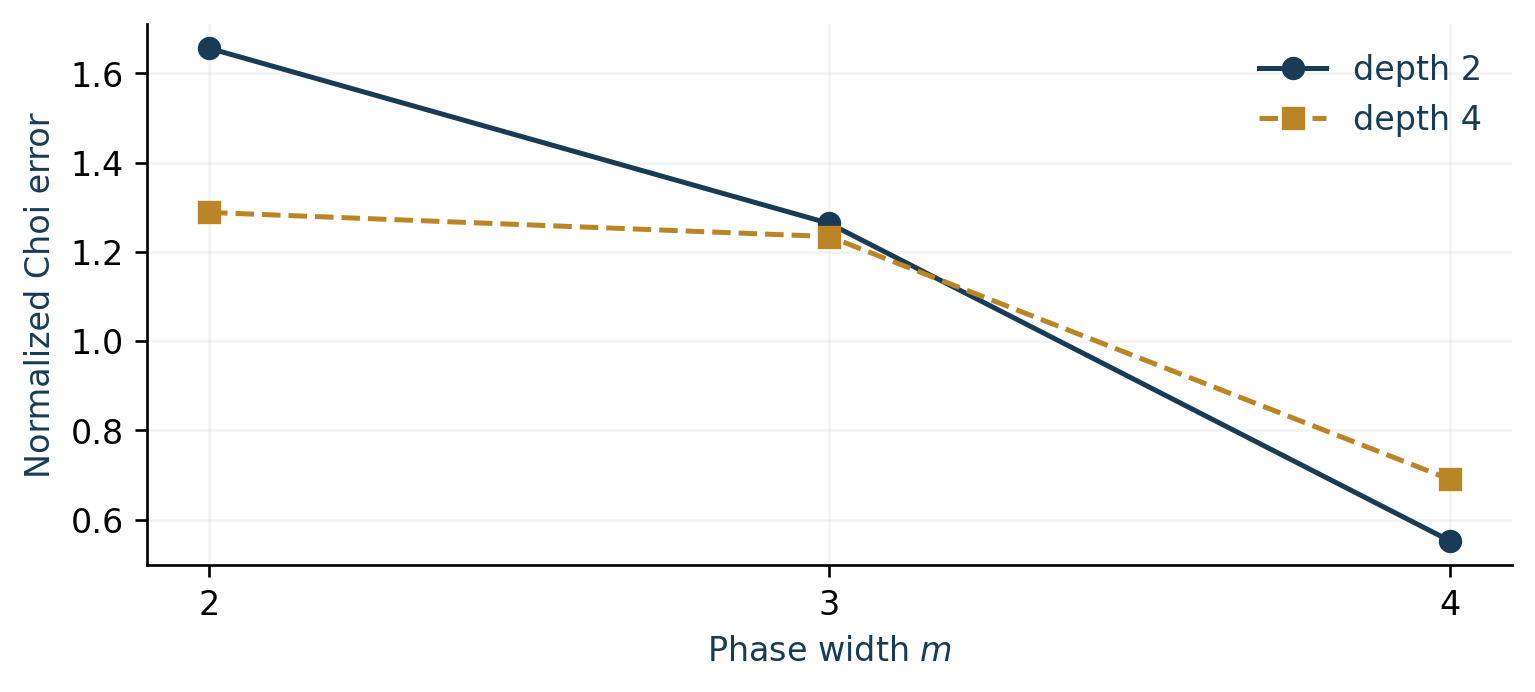

### A02 bounds

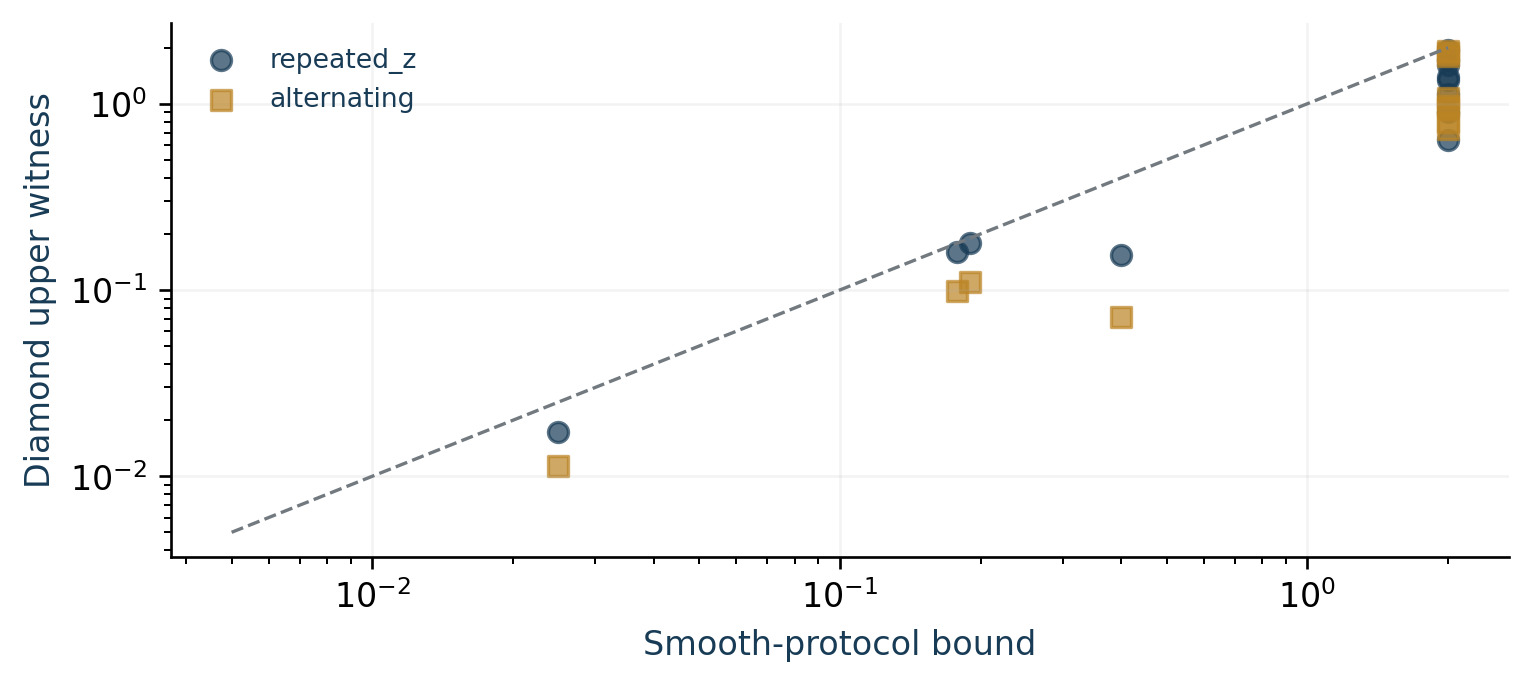

In [4]:
subprocess.run([sys.executable,str(ROOT/'reproduce.py'),'figures'],cwd=ROOT,check=True)
from IPython.display import display, Image, Markdown
names=['00_research_overview','C01_qru_loading','C02_service_estimator','01_contract','02_precision','03_memory','04_fibre','05_noise','C03_grover_window','C04_target_control','A_resources','A_calibration','A_06_bit_allocation','A_03_scalar_vs_channel','A_07_quaternion_fibre','A_02_fibre_cancellation','A_04_dephasing_intervention','A_reuse','A01_depth','A02_bounds']
for name in names:
    display(Markdown('### '+name.replace('_',' ')))
    display(Image(filename=str(ROOT/'outputs/figures'/f'{name}.png'),width=700))

## Complete numerical rerun
Run the following separately to regenerate all eight campaigns, compare their CSVs to the reference tables and render figures from the recomputed data. The scripts write progress under `outputs/results/`.

In [5]:
# subprocess.run([sys.executable,'reproduce.py','experiments'],cwd=ROOT,check=True)
# subprocess.run([sys.executable,'reproduce.py','compare'],cwd=ROOT,check=True)
# subprocess.run([sys.executable,'reproduce.py','figures','--data','outputs/results'],cwd=ROOT,check=True)